# ♻️ MISSÃO RECOMEÇO
### Desafio 2 · Trilha de Visão Computacional · Olimpíada de IA Aplicada 2026

---

> **"Eu separo material há vinte e dois anos. Sei distinguir os cinco tipos pelo brilho,
> antes mesmo de tocar. A pergunta é se isso que eu sei pode ser descrito com precisão
> suficiente para uma máquina reproduzir."**
>
> — Rosa Bezerra, presidente da Cooperativa Recomeço

---

<img src="https://lh3.googleusercontent.com/d/1Qz9zzwL-EcWPeVBi5_Gz0tc5pOyGoSvm=w1600" width="100%"
     alt="Galpão de cooperativa de reciclagem: Rosa, de lenço colorido no cabelo e luvas verdes, sorri à beira da esteira. Uma câmera sobre tripé, com luz ciano, aponta para as embalagens que passam. Ao fundo, fardos e montanhas de material separado.">


## 📨 O chamado da Cooperativa Recomeço

*A sua equipe recebe um convite para visitar um galpão na periferia da cidade.
Vocês aceitam. E o que encontram lá muda a forma como vocês olham para o lixo.*

---

**De:** Cooperativa Recomeço · Setor de Triagem
**Para:** Equipe de Engenharia de Visão Computacional

> Presido uma cooperativa com 34 associados. Recebemos cerca de seis toneladas diárias de
> material misto, separadas manualmente peça por peça.
>
> O problema é econômico e mensurável. Lotes com contaminação, por exemplo vidro
> particulado misturado ao papel, são desclassificados na venda e reduzem drasticamente a
> receita do mês. A taxa de erro na triagem manual cresce ao longo do turno, por fadiga.
>
> Fomos procurados por um grupo da universidade que sugeriu classificação automática por
> imagem. Não domino a técnica, mas domino o material, e talvez seja aí que eu possa
> contribuir com vocês.
>
> **Cada material tem uma assinatura óptica distinta.** O papel é fosco, de reflexão
> difusa. O papelão também é fosco, mas é mais escuro e tem textura de ondulação. O
> plástico tem cor saturada e superfície regular. O vidro é parcialmente translúcido e
> produz reflexos concentrados. O metal tem reflexão especular intensa, quase sempre em
> faixas.
>
> Reparem que eu acabei de descrever, com as palavras que tenho, propriedades que são
> mensuráveis. Suspeito que seja exatamente isso que vocês precisam extrair.
>
> Instalamos uma câmera sobre a esteira e registramos alguns milhares de imagens,
> rotuladas por tipo. **Aviso que as condições não são de laboratório:** a iluminação do
> galpão varia ao longo do dia e o material chega sujo. É o dado real que temos.
>
> Duas advertências. **Papel e papelão são a dupla que mais confunde**, inclusive gente
> experiente. E os cinco tipos não chegam em quantidades iguais: entra bem mais papel do
> que papelão, e isso é a nossa rotina, não um defeito da amostra.
>
> — Rosa Bezerra

---

*As observações finais da mensagem não são detalhes. Elas definem a dificuldade do problema.*


## 🎯 A sua missão

Construir um modelo de IA que **olha uma foto de um material** e diz se é
**papel**, **papelão**, **plástico**, **vidro** ou **metal**.

### O problema da representação

Uma imagem digital é uma matriz de intensidades: cada pixel guarda três valores, um por
canal de cor. Uma imagem de 48 por 48 pixels contém, portanto, 6.912 valores. Entregar essa
matriz bruta a um classificador clássico é inviável por dois motivos: a dimensionalidade é
alta demais em relação ao número de exemplos disponíveis, e a representação por pixel é
frágil, já que qualquer deslocamento do objeto altera completamente o vetor.

A alternativa clássica, e a que este desafio adota, é a **extração de características**:
substituir os milhares de valores brutos por um conjunto pequeno de medidas que descrevem
propriedades globais da imagem, como brilho médio, contraste, saturação, densidade de
bordas e proporção de área com alta luminância.

Reparem no que a Rosa fez na mensagem. Ao descrever reflexão difusa, saturação e reflexo
especular, ela enunciou, em linguagem natural, um conjunto de descritores. **Conhecimento
de domínio é o que orienta a escolha das características**, e é por isso que projetos de IA
aplicada dão errado quando a equipe técnica não conversa com quem entende do problema.

> Consequência prática: depois da extração, cada imagem passa a ser uma linha de uma
> tabela, e o problema se reduz a uma classificação tabular convencional. Os mesmos
> algoritmos e a mesma interface do desafio anterior voltam a valer.

### 🗺️ O mapa da missão

| Bloco | O que vocês fazem | Como |
|:---|:---|:---|
| **1 · EXPLORAR** | Ver as fotos da esteira e descobrir o que separa cada material | Só clicando |
| **2 · CONFIGURAR** | Decidir quais características usar e como treinar | Só arrastando |
| **3 · MODELAR** | Ensinar o modelo a enxergar | ✏️ Completando o código |
| **4 · AVALIAR** | Descobrir onde o modelo se confunde, e por quê | Só clicando |

> ⚠️ Confirme que o ambiente está em **CPU** (`Ambiente de execução` → `Alterar o tipo`).
> Não usamos rede neural pesada aqui: nosso modelo roda em **segundos**, e mesmo assim
> aprende muito bem. Inteligência não é sinônimo de peso.


In [29]:
#@title 🛠️ Preparação: recebendo as fotos da esteira { display-mode: "form" }
# Endereços oficiais dos dados. A organização republica aqui se precisar trocar.
URL_TREINO_FOTOS = "https://drive.google.com/uc?export=download&id=1lJRXzTupXGUrn3R6tdnA7ulROYEEe7RX"
URL_TESTE_FOTOS = "https://drive.google.com/uc?export=download&id=10gpTF72qwQ7a15Q-ZruntCnlB59RPSGD"

import pathlib, warnings
import numpy as np, pandas as pd
from scipy import ndimage
from scipy.stats import skew, kurtosis
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import threshold_otsu
from matplotlib.colors import rgb_to_hsv
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

CLASSES = ["papel", "papelao", "plastico", "vidro", "metal"]
EMOJI   = {"papel":"📄", "papelao":"📦", "plastico":"🧴", "vidro":"🍾", "metal":"🥫"}


from skimage.color import rgb2gray
from skimage.transform import hough_line

# Geometria calculada por imagem: nunca usa rotulos ou estatisticas de outras fotos.
def localizar_reflexos(im):
    rgb = np.asarray(im, dtype=np.float64)
    if np.issubdtype(np.asarray(im).dtype, np.integer):
        rgb = rgb / 255.0
    if rgb.ndim != 3 or rgb.shape[2] != 3 or not np.isfinite(rgb).all():
        raise ValueError("Esperada uma imagem RGB finita com shape (altura, largura, 3).")
    if rgb.min() < 0 or rgb.max() > 1:
        raise ValueError("RGB deve estar em [0,1] ou uint8 em [0,255].")
    altura, largura = rgb.shape[:2]
    cinza = rgb2gray(rgb)  # luminancia ponderada; preserva o RGB original
    p10, p90 = np.percentile(cinza, [10, 90])
    # Um quantil sozinho marcaria uma imagem constante inteira como reflexo.
    mascara = (cinza >= p90) & (cinza > p10 + 1e-6)
    theta = np.linspace(-np.pi / 2, np.pi / 2, 36, endpoint=False)
    acumulador, angulos, distancias = hough_line(mascara, theta=theta)
    return rgb, cinza, mascara, acumulador, angulos, distancias


def descritores_espaciais(im):
    rgb, cinza, mascara, hough, angulos, distancias = localizar_reflexos(im)
    altura, largura = cinza.shape
    diagonal = np.hypot(altura, largura)
    quantidade = int(mascara.sum())
    linhas, colunas_px = np.nonzero(mascara)
    f = {
        "meta_altura": altura, "meta_largura": largura,
        "meta_proporcao": largura / altura, "meta_pixels": altura * largura,
        "luma_media": cinza.mean(), "luma_desvio": cinza.std(),
    }
    # Projecoes localizam linhas/colunas claras sem assumir onde o objeto aparece.
    for nome, perfil in [("linha", mascara.mean(axis=1)),
                          ("coluna", mascara.mean(axis=0))]:
        f[f"reflexo_{nome}_forca"] = perfil.max()
        f[f"reflexo_{nome}_posicao"] = (
            perfil.argmax() / max(1, len(perfil) - 1) if quantidade else 0.0)
        f[f"reflexo_{nome}_dispersao"] = perfil.std()

    # x*cos(theta) + y*sin(theta) = rho: inclui as duas diagonais.
    for nome, theta in [("vertical", 0), ("horizontal", -np.pi/2),
                         ("diagonal_mais", np.pi/4),
                         ("diagonal_menos", -np.pi/4)]:
        j = int(np.abs(angulos - theta).argmin())
        i = int(hough[:, j].argmax())
        f[f"faixa_{nome}_forca"] = hough[i, j] / diagonal
        if "diagonal" in nome:
            f[f"faixa_{nome}_posicao"] = distancias[i] / diagonal if quantidade else 0.0

    i, j = np.unravel_index(hough.argmax(), hough.shape)
    f["faixa_forca_maxima"] = hough[i, j] / diagonal
    # Orientacao axial: angulos separados por 180 graus representam a mesma linha.
    f["faixa_orientacao_seno"] = np.sin(2 * angulos[j]) if quantidade else 0.0
    f["faixa_orientacao_cosseno"] = np.cos(2 * angulos[j]) if quantidade else 0.0
    f["faixa_distancia_centro"] = (
        abs(distancias[i] - (largura-1)/2*np.cos(angulos[j])
            - (altura-1)/2*np.sin(angulos[j])) / diagonal if quantidade else 0.0)

    # Metadados da REGIAO brilhante variam mesmo quando a imagem tem tamanho fixo.
    regioes, n = ndimage.label(mascara)
    tamanhos = np.bincount(regioes.ravel(), minlength=n+1)[1:]
    f["reflexo_maior_area"] = tamanhos.max() / mascara.size if n else 0.0
    f["reflexo_fragmentacao"] = np.count_nonzero(tamanhos >= 3) / max(1, quantidade)
    f["reflexo_centro_x"] = colunas_px.mean()/max(1, largura-1) if quantidade else 0.0
    f["reflexo_centro_y"] = linhas.mean()/max(1, altura-1) if quantidade else 0.0
    f["reflexo_linearidade"] = 0.0
    if quantidade >= 3:
        autovalores = np.linalg.eigvalsh(np.cov(np.vstack([colunas_px, linhas])))
        f["reflexo_linearidade"] = (
            (autovalores[1]-autovalores[0]) / (autovalores.sum()+1e-12))
    # Cor do reflexo e contraste local: separa faixa especular de fundo apenas claro.
    f["reflexo_contraste_fundo"] = (
        cinza[mascara].mean()-cinza[~mascara].mean()
        if quantidade and (~mascara).any() else 0.0)
    mx, mn = rgb.max(axis=2), rgb.min(axis=2)
    saturacao = (mx-mn)/(mx+1e-12)
    f["reflexo_saturacao"] = saturacao[mascara].mean() if quantidade else 0.0
    # Cromaticidade RGB normalizada por pixel, sem ajustar estatisticas globais.
    soma = rgb.sum(axis=2) + 1e-12
    f["rgb_relativo_vermelho"] = (rgb[..., 0]/soma).mean()
    f["rgb_relativo_verde"] = (rgb[..., 1]/soma).mean()
    return f


def extrair_caracteristicas(fotos):
    """👀 Transforma cada FOTO em uma LINHA DE NÚMEROS que o modelo entende."""
    L = []
    for im in fotos:
        cinza = im.mean(axis=2)
        gx = np.abs(np.diff(cinza, axis=1)).mean()
        gy = np.abs(np.diff(cinza, axis=0)).mean()
        mx, mn = im.max(axis=2), im.min(axis=2)
        satur  = np.where(mx > 0, (mx - mn) / (mx + 1e-6), 0)

        # FASE 2: estatísticas circulares da matiz HSV (0 e 1 são vizinhos).
        hue = rgb_to_hsv(im)[..., 0]
        angulos_hue = 2 * np.pi * hue
        seno_medio = np.sin(angulos_hue).mean()
        cosseno_medio = np.cos(angulos_hue).mean()
        hue_medio = (np.arctan2(seno_medio, cosseno_medio) % (2 * np.pi)) / (2 * np.pi)
        resultante_hue = np.clip(np.hypot(seno_medio, cosseno_medio), 1e-12, 1.0)
        hue_variacao = np.sqrt(-2 * np.log(resultante_hue)) / (2 * np.pi)

        # FASE 3: forma da distribuição de brilho; imagens constantes recebem zero.
        brilho_assimetria = float(np.nan_to_num(skew(cinza.ravel()), nan=0.0))
        brilho_curtose = float(np.nan_to_num(kurtosis(cinza.ravel()), nan=0.0))

        # FASE 4: fração da energia em frequências médias dos perfis 1D.
        def energia_media_fft(perfil):
            espectro = np.abs(np.fft.rfft(perfil - perfil.mean())) ** 2
            frequencias = np.fft.rfftfreq(len(perfil))
            faixa_media = (frequencias >= 0.08) & (frequencias <= 0.30)
            return espectro[faixa_media].sum() / (espectro[1:].sum() + 1e-12)
        energia_periodica = max(
            energia_media_fft(cinza.mean(axis=1)),
            energia_media_fft(cinza.mean(axis=0)))

        # FASE 6: o fundo é a moda do histograma; Otsu separa desvios dessa moda.
        histograma, limites = np.histogram(cinza, bins=32, range=(0, 1))
        indice_fundo = histograma.argmax()
        fundo_dominante = (limites[indice_fundo] + limites[indice_fundo + 1]) / 2
        distancia_fundo = np.abs(cinza - fundo_dominante)
        if np.ptp(distancia_fundo) <= 1e-12:
            proporcao_objeto = 0.0
        else:
            limiar_objeto = threshold_otsu(distancia_fundo)
            proporcao_objeto = (distancia_fundo > limiar_objeto).mean()

        # ETAPA 3: geometria do reflexo. Entre os 10% pixels mais claros,
        # mede o alongamento da maior região conectada (faixa de brilho).
        brilho_p90 = np.percentile(cinza, 90)
        mascara_reflexo = cinza >= brilho_p90
        regioes, _ = ndimage.label(mascara_reflexo)
        tamanhos = np.bincount(regioes.ravel())
        tamanhos[0] = 0  # ignora o fundo
        # Conta apenas componentes com pelo menos 3 pixels para filtrar ruído isolado.
        n_regioes_reflexo = np.count_nonzero(tamanhos >= 3)
        maior_regiao = tamanhos.argmax()
        linhas, colunas_reflexo = np.where(regioes == maior_regiao)
        altura = linhas.max() - linhas.min() + 1
        largura = colunas_reflexo.max() - colunas_reflexo.min() + 1
        alongamento_reflexo = max(altura, largura) / max(1, min(altura, largura))

        # ETAPA 4: textura fina para distinguir principalmente papel e papelão.
        grad_x = np.abs(np.diff(cinza, axis=1))
        grad_y = np.abs(np.diff(cinza, axis=0))
        gradiente_local = np.hypot(grad_x[:-1, :], grad_y[:, :-1])
        variancia_laplaciano = ndimage.laplace(cinza).var()
        densidade_bordas = (gradiente_local > 0.05).mean()
        cinza_16_niveis = np.clip((cinza * 15).astype(np.uint8), 0, 15)
        glcm = graycomatrix(
            cinza_16_niveis, distances=[1],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=16, symmetric=True, normed=True)
        glcm_contrast = graycoprops(glcm, "contrast").mean()
        glcm_homogeneity = graycoprops(glcm, "homogeneity").mean()
        # FASE 5: propriedades adicionais reaproveitam a mesma GLCM.
        glcm_energy = graycoprops(glcm, "energy").mean()
        glcm_correlation = graycoprops(glcm, "correlation").mean()

        # ETAPA 5: extremos da distribuição de saturação para plástico.
        saturacao_p25 = np.percentile(satur, 25)
        saturacao_p90 = np.percentile(satur, 90)
        L.append([im[...,0].mean(), im[...,1].mean(), im[...,2].mean(),
                  im[...,0].std(),  im[...,1].std(),  im[...,2].std(),
                  cinza.mean(), cinza.std(), np.percentile(cinza, 95),
                  np.percentile(cinza, 95) - np.percentile(cinza, 5),
                  (gx + gy) / 2, satur.mean(), satur.std(),
                  (cinza > .80).mean(), alongamento_reflexo, n_regioes_reflexo,
                  variancia_laplaciano, densidade_bordas,
                  glcm_contrast, glcm_homogeneity,
                  saturacao_p25, saturacao_p90, brilho_p90,
                  hue_medio, hue_variacao, brilho_assimetria, brilho_curtose,
                  energia_periodica, glcm_energy, glcm_correlation,
                  proporcao_objeto])
    tabela_base = pd.DataFrame(L, columns=[
        "vermelho_medio","verde_medio","azul_medio",
        "vermelho_variacao","verde_variacao","azul_variacao",
        "brilho_medio","contraste","brilho_alto",
        "amplitude_luz","bordas","saturacao_media","saturacao_variacao",
        "area_reluzente","alongamento_reflexo","n_regioes_reflexo",
        "variancia_laplaciano","densidade_bordas",
        "glcm_contrast","glcm_homogeneity",
        "saturacao_p25","saturacao_p90","brilho_p90",
        "hue_medio","hue_variacao","brilho_assimetria","brilho_curtose",
        "energia_periodica","glcm_energy","glcm_correlation",
        "proporcao_objeto"])
    tabela_espacial = pd.DataFrame([descritores_espaciais(im) for im in fotos])
    return pd.concat([tabela_base, tabela_espacial], axis=1)


def _npz(url, nome_local):
    """Baixa do endereço oficial; sem endereço ou sem rede, pede o envio."""
    if url and not pathlib.Path(nome_local).exists():
        import urllib.request
        try:
            print(f"Baixando {nome_local}...")
            urllib.request.urlretrieve(url, nome_local)
        except Exception as erro:
            print(f"  não deu certo ({erro.__class__.__name__}).")
    if not pathlib.Path(nome_local).exists():
        from google.colab import files
        print(f"Envie o arquivo {nome_local}:")
        files.upload()
    return np.load(nome_local, allow_pickle=False)


# As fotos vêm em uint8 (0-255), como qualquer imagem; o modelo trabalha em [0,1].
_treino = _npz(URL_TREINO_FOTOS, "treino_fotos.npz")
_teste = _npz(URL_TESTE_FOTOS, "teste_fotos.npz")

# Conjunto PÚBLICO: rotulado. Serve para treinar e validar.
fotos = _treino["fotos"].astype(np.float32) / 255.0
rotulos = _treino["rotulos"]

# Conjunto de TESTE: tamanho fixo, rótulos ocultos. Base da comparação oficial.
fotos_teste = _teste["fotos"].astype(np.float32) / 255.0
N_TESTE = len(fotos_teste)

print("Ambiente carregado.")
print(f"  Conjunto público (rotulado) ....... {len(fotos):>4} imagens, {len(CLASSES)} materiais")
print(f"  Conjunto de teste (sem rótulo) .... {len(fotos_teste):>4} imagens  [tamanho fixo]")
print(f"  Cada imagem: {fotos.shape[1]}x{fotos.shape[2]} pixels x 3 canais = "
      f"{fotos.shape[1]*fotos.shape[2]*3:,} valores")
print(f"\n  A submissão precisará ter exatamente {N_TESTE} linhas.")
print("\n   A etapa seguinte reduz essa representação a um conjunto pequeno")
print("   de descritores com poder discriminante.")

Ambiente carregado.
  Conjunto público (rotulado) ....... 2150 imagens, 5 materiais
  Conjunto de teste (sem rótulo) ....  240 imagens  [tamanho fixo]
  Cada imagem: 48x48 pixels x 3 canais = 6,912 valores

  A submissão precisará ter exatamente 240 linhas.

   A etapa seguinte reduz essa representação a um conjunto pequeno
   de descritores com poder discriminante.


---
# 🔍 BLOCO 1 · EXPLORAR
## *Olhem com os olhos da Dona Rosa*

> **Rosa:** *"Antes de programar qualquer coisa, olhem o material. Vocês precisam
> conseguir descrever a diferença antes de tentar medi-la."*

Cada propriedade que vocês conseguirem verbalizar nesta etapa corresponde a um descritor
que pode ser calculado. A qualidade da representação depende dessa observação inicial.


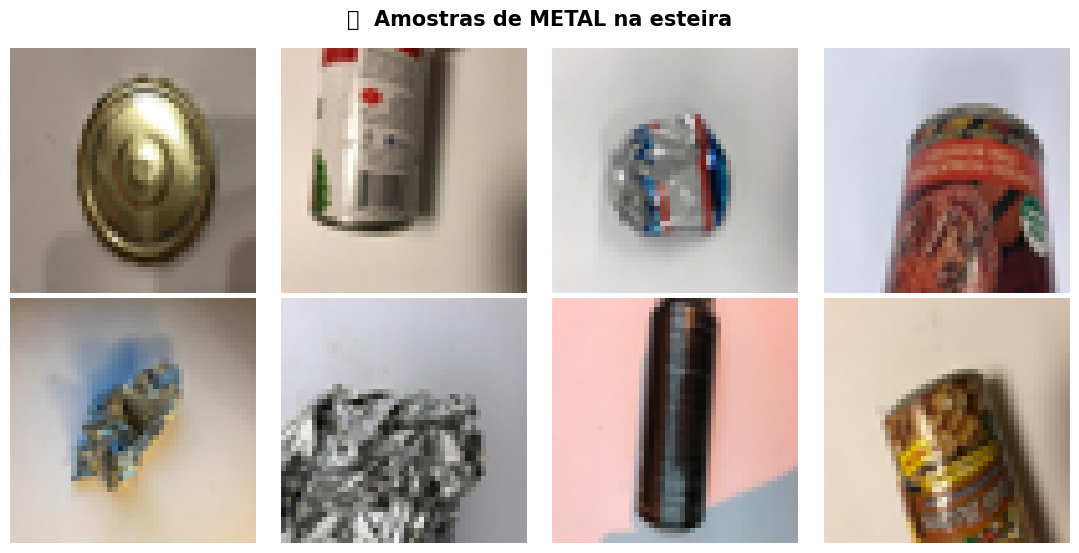

Analisem as amostras de METAL sob quatro dimensões:
   Luminância    - a superfície é clara ou escura, e quão uniforme é?
   Saturação     - a cor é intensa ou próxima do acromático?
   Reflectância  - a reflexão é difusa (espalhada) ou especular (concentrada)?
   Textura       - há variação local de intensidade ou a superfície é homogênea?

Alternem entre os materiais e registrem quais dimensões os separam melhor.
Essa análise antecipa quais descritores terão poder discriminante.


In [30]:
#@title 📷 As fotos da esteira { display-mode: "form" }
#@markdown Escolha um material e rode a célula (▶) para ver oito fotos dele.
material = "metal"  #@param ["papel", "papelao", "plastico", "vidro", "metal"]

idx = np.where(rotulos == material)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(fotos[i]); ax.axis("off")
fig.suptitle(f"{EMOJI[material]}  Amostras de {material.upper()} na esteira",
             fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Analisem as amostras de {material.upper()} sob quatro dimensões:")
print("   Luminância    - a superfície é clara ou escura, e quão uniforme é?")
print("   Saturação     - a cor é intensa ou próxima do acromático?")
print("   Reflectância  - a reflexão é difusa (espalhada) ou especular (concentrada)?")
print("   Textura       - há variação local de intensidade ou a superfície é homogênea?")
print("\nAlternem entre os materiais e registrem quais dimensões os separam melhor.")
print("Essa análise antecipa quais descritores terão poder discriminante.")

In [31]:
#@title 🔢 Extração de características: de imagem para vetor { display-mode: "form" }
# Esta célula transforma **todas as fotos** em uma tabela de características.
# É o passo que faz um problema de imagem virar um problema de tabela.
X_caract = extrair_caracteristicas(fotos)
X_caract_teste = extrair_caracteristicas(fotos_teste)

print("Extração concluída.\n")
print(f"   Representação bruta:    {fotos.shape[1]*fotos.shape[2]*3:,} valores por imagem")
print(f"   Representação extraída: {X_caract.shape[1]} valores por imagem\n")
tabela = X_caract.copy(); tabela.insert(0, "material", rotulos)
display(tabela.head())
print("\nO objeto resultante é uma tabela convencional. O problema de visão foi")
print("reduzido a um problema tabular, e assim será tratado daqui em diante.")

Extração concluída.

   Representação bruta:    6,912 valores por imagem
   Representação extraída: 62 valores por imagem



,material,vermelho_medio,verde_medio,azul_medio,vermelho_variacao,verde_variacao,azul_variacao,brilho_medio,contraste,brilho_alto,...,faixa_distancia_centro,reflexo_maior_area,reflexo_fragmentacao,reflexo_centro_x,reflexo_centro_y,reflexo_linearidade,reflexo_contraste_fundo,reflexo_saturacao,rgb_relativo_vermelho,rgb_relativo_verde
0,metal,0.533264,0.488542,0.420016,0.152371,0.158257,0.172631,0.480607,0.159451,0.683660,...,0.117851,0.066840,0.038961,0.574929,0.302938,0.432854,0.300252,0.191362,0.379267,0.341087
1,papel,0.755886,0.746572,0.728345,0.161172,0.173827,0.185952,0.743601,0.173351,0.903268,...,0.095754,0.057726,0.017316,0.435111,0.469743,0.888348,0.185358,0.013267,0.341326,0.334672
2,papelao,0.708429,0.649215,0.561417,0.180570,0.188570,0.195047,0.639687,0.181680,0.877124,...,0.346188,0.083767,0.021645,0.331675,0.874827,0.040977,0.248041,0.070816,0.375346,0.336980
3,papel,0.778048,0.742793,0.699088,0.105302,0.081849,0.089520,0.739977,0.089712,0.841830,...,0.162045,0.100260,0.008299,0.200671,0.548954,0.549108,0.109821,0.066023,0.349567,0.335306
4,vidro,0.591457,0.554065,0.516828,0.057658,0.057403,0.057752,0.554117,0.057538,0.627451,...,0.298075,0.110677,0.007576,0.204626,0.140877,0.443303,0.082548,0.119086,0.356060,0.333313



O objeto resultante é uma tabela convencional. O problema de visão foi
reduzido a um problema tabular, e assim será tratado daqui em diante.


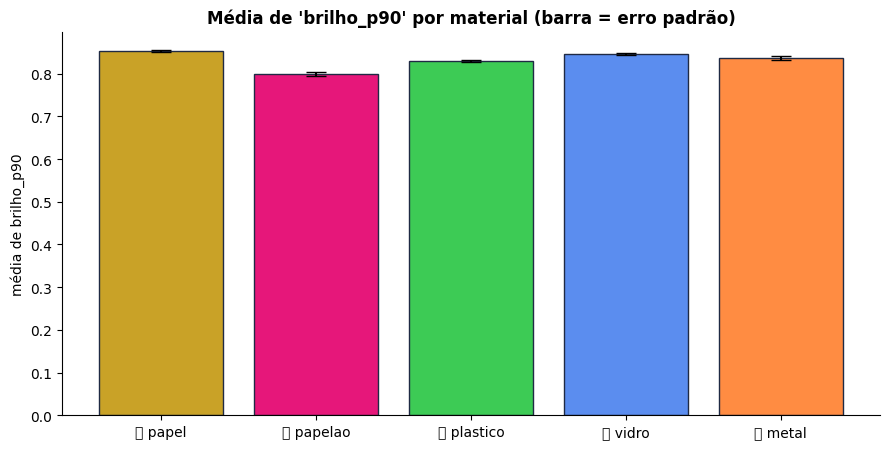

Média de 'brilho_p90':
   📄 papel     0.853
   📦 papelao   0.799
   🧴 plastico  0.830
   🍾 vidro     0.846
   🥫 metal     0.837

Amplitude entre classes: 0.054
   Observem também a SOBREPOSIÇÃO entre as distribuições: classes com médias
   distantes mas grande dispersão continuam difíceis de separar por essa
   variável isoladamente. Nenhum descritor precisa separar tudo sozinho.

SUGESTÃO: use a Dispersão para cruzar dois descritores e procurar pares que
   separem classes que um descritor sozinho não separa.


In [32]:
#@title 📊 Investigue os descritores: escolha a variável E o tipo de gráfico { display-mode: "form" }
#@markdown Escolha o descritor e o gráfico, depois rode a célula (▶).
caracteristica = "brilho_p90"  #@param ["vermelho_medio", "verde_medio", "azul_medio", "vermelho_variacao", "verde_variacao", "azul_variacao", "brilho_medio", "contraste", "brilho_alto", "amplitude_luz", "bordas", "saturacao_media", "saturacao_variacao", "area_reluzente", "alongamento_reflexo", "variancia_laplaciano", "densidade_bordas", "glcm_contrast", "glcm_homogeneity", "saturacao_p25", "saturacao_p90", "brilho_p90"]
tipo_de_grafico = "Barras de media"  #@param ["Boxplot", "Histograma sobreposto", "Violino", "Barras de media", "Dispersao contra outro descritor", "Galeria por faixa do descritor"]
segundo_descritor = "azul_medio"  #@param ["vermelho_medio", "verde_medio", "azul_medio", "brilho_medio", "contraste", "bordas", "saturacao_media", "area_reluzente", "amplitude_luz", "alongamento_reflexo", "variancia_laplaciano", "densidade_bordas", "glcm_contrast", "glcm_homogeneity", "saturacao_p25", "saturacao_p90", "brilho_p90"]

CORES_G = ["#C9A227", "#E6177A", "#3DCB55", "#5B8DEF", "#FF8C42"]
grupos = [X_caract[rotulos == c][caracteristica] for c in CLASSES]
rot_leg = [f"{EMOJI[c]} {c}" for c in CLASSES]

fig, ax = plt.subplots(figsize=(9, 4.6))

if tipo_de_grafico == "Boxplot":
    bp = ax.boxplot(grupos, patch_artist=True, tick_labels=rot_leg,
                    medianprops=dict(color="black", linewidth=2))
    for p, c in zip(bp["boxes"], CORES_G): p.set_facecolor(c); p.set_alpha(.8)
    ax.set_ylabel(caracteristica)
    ax.set_title(f"'{caracteristica}' por material (mediana, quartis e extremos)", fontweight="bold")

elif tipo_de_grafico == "Histograma sobreposto":
    bins = np.histogram_bin_edges(X_caract[caracteristica], bins=28)
    for g, c, r in zip(grupos, CORES_G, CLASSES):
        ax.hist(g, bins=bins, alpha=.55, label=r, color=c, edgecolor="white")
    ax.legend(); ax.set_xlabel(caracteristica); ax.set_ylabel("quantidade")
    ax.set_title(f"Distribuição de '{caracteristica}' por material", fontweight="bold")

elif tipo_de_grafico == "Violino":
    vp = ax.violinplot(grupos, showmedians=True)
    for corpo, c in zip(vp["bodies"], CORES_G): corpo.set_facecolor(c); corpo.set_alpha(.75)
    ax.set_xticks(range(1, len(CLASSES) + 1)); ax.set_xticklabels(rot_leg)
    ax.set_ylabel(caracteristica)
    ax.set_title(f"Densidade de '{caracteristica}' por material", fontweight="bold")

elif tipo_de_grafico == "Barras de media":
    med = [g.mean() for g in grupos]; err = [g.std()/np.sqrt(len(g)) for g in grupos]
    ax.bar(rot_leg, med, yerr=err, capsize=7, color=CORES_G, edgecolor="#1F2A44")
    ax.set_ylabel(f"média de {caracteristica}")
    ax.set_title(f"Média de '{caracteristica}' por material (barra = erro padrão)", fontweight="bold")

elif tipo_de_grafico == "Dispersao contra outro descritor":
    for c, cor in zip(CLASSES, CORES_G):
        sub = X_caract[rotulos == c]
        ax.scatter(sub[caracteristica], sub[segundo_descritor], s=16, alpha=.6,
                   color=cor, label=c, edgecolors="none")
    ax.set_xlabel(caracteristica); ax.set_ylabel(segundo_descritor); ax.legend()
    ax.set_title(f"'{caracteristica}' contra '{segundo_descritor}'", fontweight="bold")

else:  # Galeria por faixa
    plt.close(fig)
    ordem = np.argsort(X_caract[caracteristica].values)
    baixos, altos = ordem[:5], ordem[-5:]
    fig, axes = plt.subplots(2, 5, figsize=(11.5, 5))
    for linha, grupo in ((0, baixos), (1, altos)):
        for ax_, i in zip(axes[linha], grupo):
            ax_.imshow(fotos[i]); ax_.axis("off")
            ax_.set_title(f"{rotulos[i]}\n{X_caract[caracteristica].iloc[i]:.3f}", fontsize=8)
    fig.suptitle(f"Imagens com os MENORES (acima) e MAIORES (abaixo) valores de "
                 f"'{caracteristica}'", fontweight="bold")
    plt.tight_layout(); plt.show()
    print("Esta visualização conecta o número à imagem: vejam o que de fato muda")
    print(f"na aparência do material entre os extremos de '{caracteristica}'.")
    print("É a forma mais direta de verificar se um descritor mede o que vocês supõem.")

if tipo_de_grafico != "Galeria por faixa do descritor":
    ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout(); plt.show()
    m = pd.Series({c: X_caract[rotulos == c][caracteristica].mean() for c in CLASSES})
    print(f"Média de '{caracteristica}':")
    for c in CLASSES: print(f"   {EMOJI[c]} {c:<9} {m[c]:.3f}")
    print(f"\nAmplitude entre classes: {m.max()-m.min():.3f}")
    print("   Observem também a SOBREPOSIÇÃO entre as distribuições: classes com médias")
    print("   distantes mas grande dispersão continuam difíceis de separar por essa")
    print("   variável isoladamente. Nenhum descritor precisa separar tudo sozinho.")
    print("\nSUGESTÃO: use a Dispersão para cruzar dois descritores e procurar pares que")
    print("   separem classes que um descritor sozinho não separa.")

> **Rosa:** *"A reflexão especular do metal aparece nos números de vocês. Era o que eu
> esperava. O difícil vai ser o vidro."*

<img src="https://lh3.googleusercontent.com/d/1SEXPNOB_d56gI0Ixd3ws5l0x5x-RhLRf=w1600" width="100%"
     alt="Cena dividida ao meio: à esquerda, uma lata de alumínio amassada sobre a esteira; à direita, a mesma lata redesenhada como uma grade luminosa de números, dígitos binários e histogramas. Feixes de luz ciano ligam os dois lados.">


---
# ⚙️ BLOCO 2 · CONFIGURAR
## *As decisões que definem o desempenho*

### Como os dados estão organizados

| Conjunto | Tamanho | Vocês têm os rótulos? | Para que serve |
|:---|:---|:---|:---|
| **Público** | 2.150 imagens | Sim | Treinar o modelo e validar as escolhas |
| **Teste** | **240 (fixo)** | Não | Comparação oficial entre todas as equipes |

O controle abaixo define que fatia do conjunto público fica reservada para **validação**.
O conjunto de teste tem tamanho fixo e igual para todas as equipes, e a submissão precisa
ter exatamente 240 linhas.


In [33]:
#@title 🎛️ Parâmetros do experimento { display-mode: "form" }
#@markdown Ajuste os controles e rode a célula (▶) para registrar a configuração.
tamanho_da_validacao = 10  #@param {type:"slider", min:10, max:40, step:5}
conjunto_de_caracteristicas = "todas"  #@param ["todas", "so cor", "so brilho e textura"]
modelo_escolhido = "SVM"  #@param ["Regressao Logistica", "Floresta Aleatoria", "SVM"]
padronizar = True  #@param {type:"boolean"}
forca_C = 30  #@param {type:"slider", min:0.01, max:200, step:0.01}

GRUPOS = {
    "todas": list(X_caract.columns),
    "so cor": ["vermelho_medio","verde_medio","azul_medio","saturacao_media",
               "saturacao_variacao","saturacao_p25","saturacao_p90",
               "vermelho_variacao","verde_variacao","azul_variacao"],
    "so brilho e textura": ["brilho_medio","contraste","brilho_alto","amplitude_luz",
                            "bordas","area_reluzente","alongamento_reflexo",
                            "variancia_laplaciano","densidade_bordas",
                            "glcm_contrast","glcm_homogeneity","brilho_p90"]}
colunas = GRUPOS[conjunto_de_caracteristicas]

print("PARÂMETROS DEFINIDOS")
print(f"   Validação .......... {tamanho_da_validacao}% do conjunto público")
print(f"   Descritores ........ {conjunto_de_caracteristicas} ({len(colunas)} variáveis)")
print(f"   Modelo ............. {modelo_escolhido}")
print(f"   Padronizar ......... {'sim' if padronizar else 'não'}")
print(f"   Força C ............ {forca_C}")
print(f"   Teste .............. {len(fotos_teste)} imagens  [FIXO para todas as equipes]")
print("\nConfiguração registrada. Ela será usada nas próximas células.")

PARÂMETROS DEFINIDOS
   Validação .......... 10% do conjunto público
   Descritores ........ todas (62 variáveis)
   Modelo ............. SVM
   Padronizar ......... sim
   Força C ............ 30
   Teste .............. 240 imagens  [FIXO para todas as equipes]

Configuração registrada. Ela será usada nas próximas células.


### Seleção de descritores e padronização

**Seleção de características.** Fornecer todos os descritores nem sempre maximiza o
desempenho. Variáveis com baixo poder discriminante adicionam ruído ao espaço de entrada.
Restringir o conjunto é uma forma de regularização.

**Padronização.** Os descritores têm escalas distintas. Modelos que operam sobre
distâncias, como o SVM, ou que dependem de otimização por gradiente, como a regressão
logística, são sensíveis a essa disparidade: variáveis de maior amplitude dominam a função
objetivo independentemente de sua relevância. Modelos baseados em árvores são invariantes a
transformações monotônicas e não se beneficiam disso.

---

### 📗 Referência técnica: nome exato e parâmetros de cada classe

**Vocês vão precisar desta tabela no Bloco 3.**

> **Por que isso importa.** No Bloco 3, apenas alguns parâmetros aparecem preenchidos.
> Todos os demais assumem silenciosamente o valor padrão. Completar só o nome da classe
> produz um resultado correto e mediano. Estudar esta tabela e **acrescentar parâmetros
> à chamada** produz resultados consistentemente melhores. A diferença é intencional.

#### 🔧 Padronizador

```python
from sklearn.preprocessing import StandardScaler
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `with_mean` | `True` | Subtrai a média de cada variável |
| `with_std` | `True` | Divide pelo desvio-padrão |
| `copy` | `True` | Se opera sobre uma cópia dos dados |

#### 📈 Regressão Logística

```python
from sklearn.linear_model import LogisticRegression
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `penalty` | `'l2'` | Tipo de regularização. Aceita `'l1'`, `'l2'`, `'elasticnet'`, `None` |
| `C` | `1.0` | Inverso da força da regularização. **Menor regulariza mais** |
| `solver` | `'lbfgs'` | Algoritmo de otimização |
| `max_iter` | `100` | Iterações máximas. Frequentemente insuficiente |
| `class_weight` | `None` | `'balanced'` compensa desbalanceamento |
| `multi_class` | automático | Estratégia para mais de duas classes |
| `random_state` | `None` | Semente |

#### 🌲 Floresta Aleatória

```python
from sklearn.ensemble import RandomForestClassifier
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `n_estimators` | `100` | Número de árvores |
| `max_depth` | `None` | Profundidade máxima |
| `min_samples_leaf` | `1` | Mínimo de amostras por folha. Aumentar suaviza |
| `max_features` | `'sqrt'` | Variáveis sorteadas por corte. Aceita fração |
| `class_weight` | `None` | `'balanced'` ou `'balanced_subsample'` |
| `criterion` | `'gini'` | Alternativa: `'entropy'` |
| `n_jobs` | `None` | `-1` usa todos os núcleos |
| `random_state` | `None` | Semente |

#### 🎯 SVM

```python
from sklearn.svm import SVC
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `C` | `1.0` | Penalidade por erro. **Maior ajusta mais aos dados de treino** |
| `kernel` | `'rbf'` | Aceita `'linear'`, `'poly'`, `'rbf'`, `'sigmoid'` |
| `gamma` | `'scale'` | Alcance de influência de cada exemplo. Aceita `'auto'` ou número |
| `degree` | `3` | Grau, quando `kernel='poly'` |
| `class_weight` | `None` | `'balanced'` compensa desbalanceamento |
| `probability` | `False` | Habilita `predict_proba`, ao custo de tempo |
| `random_state` | `None` | Semente |

> 💡 No SVM, **`C` e `gamma` interagem**. Aumentar `C` sem controlar `gamma` costuma levar
> a sobreajuste. Vale testar combinações e comparar na validação.


---
# ✏️ BLOCO 3 · MODELAR
## *Aqui vocês escrevem código*

A interface é a mesma do desafio anterior: `.fit()` para ajustar, `.predict()` para inferir.
Isso decorre da decisão de representação do Bloco 1: ao converter imagens em vetores de
características, o problema passou a ser tabular.

**Sobre o `Pipeline`.** Quando a padronização está ativa, o objeto `modelo` encapsula duas
etapas: o padronizador e o classificador. Ao chamar `.fit()`, o padronizador calcula média
e desvio **apenas com os dados de treino** e repassa o resultado ao classificador. Ao
chamar `.predict()`, aplica a mesma transformação sem recalcular. Essa disciplina evita que
informação da validação influencie o ajuste.

**Sobre a estrutura condicional.** O trecho abaixo escolhe um entre três modelos conforme
a opção marcada no Bloco 2, usando uma cadeia `if` / `elif` / `else`. `else` não recebe
condição, apenas os dois-pontos.

> ⚠️ A célula não executa enquanto houver lacunas. Preencham primeiro, executem depois.


In [34]:
# ✏️ SUA VEZ · Parte 1: separar os dados e construir o modelo
# Substituam cada ____ pelo que falta. A célula só executa quando não sobrar nenhum.
X = X_caract[colunas]
y = rotulos

# LACUNA 1 ▸ 'stratify' precisa receber o vetor cuja proporção deve ser preservada
#            nas duas partes. É a tabela de descritores ou o vetor de materiais?
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)

# LACUNAS 2 a 6 ▸ os nomes exatos das classes estão na referência do Bloco 2.
#                 Faltam também as duas palavras que continuam a cadeia condicional.
if modelo_escolhido == "Regressao Logistica":
    nucleo = LogisticRegression(C=forca_C, max_iter=3000, random_state=42)

elif modelo_escolhido == "Floresta Aleatoria":
    nucleo = RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1)

else:
    nucleo = SVC(
        C=forca_C,
        kernel="rbf",
        gamma=0.07,
        class_weight=None,
        random_state=42)

# LACUNA 7 ▸ qual transformador coloca todos os descritores na mesma escala,
#            antes de o modelo vê-los? O nome está na referência do Bloco 2.
modelo = make_pipeline(StandardScaler(), nucleo) if padronizar else nucleo

# ZONA LIVRE ▸ vocês podem acrescentar parâmetros às chamadas acima.
#   As tabelas do Bloco 2 listam os disponíveis e o valor que cada um assume
#   quando não é declarado. Dois deles se destacam nesta trilha: um controla o
#   quanto o SVM se ajusta aos dados, e o outro decide se os descritores entram
#   na mesma escala. Alterem um de cada vez e comparem o F1-macro do Bloco 4.

print(f"Treino:    {len(X_treino)} imagens")
print(f"Validação: {len(X_valida)} imagens")
print(f"Modelo construído: {type(nucleo).__name__}"
      f"{' dentro de um Pipeline com StandardScaler' if padronizar else ''}")


Treino:    1935 imagens
Validação: 215 imagens
Modelo construído: SVC dentro de um Pipeline com StandardScaler


In [35]:
# import numpy as np
# import pandas as pd
# import time

# from sklearn.svm import SVC
# from sklearn.preprocessing import StandardScaler
# from sklearn.pipeline import make_pipeline
# from sklearn.metrics import f1_score, classification_report


# # ============================================================
# # NÃO CRIAMOS OUTRO TRAIN_TEST_SPLIT
# #
# # Usa diretamente:
# #
# # X_treino
# # X_valida
# # y_treino
# # y_valida
# #
# # que já foram definidos pelo notebook.
# # ============================================================


# # ============================================================
# # C E GAMMA
# # ============================================================

# Cs = [
#     5,
#     10,
#     20,
#     30,
#     50,
#     75,
#     100
# ]

# gammas = [
#     0.03,
#     0.05,
#     0.07,
#     0.10,
#     0.12,
#     0.15,
#     0.20
# ]


# # ============================================================
# # CLASS WEIGHTS
# # ============================================================

# rng = np.random.default_rng(42)

# pesos = [
#     None,
#     "balanced"
# ]


# # 24 combinações de pesos
# for _ in range(24):

#     peso = {

#         "papel": 1.0,

#         "papelao": round(
#             rng.uniform(0.80, 1.25),
#             2
#         ),

#         "plastico": round(
#             rng.uniform(0.90, 1.50),
#             2
#         ),

#         "vidro": round(
#             rng.uniform(0.80, 1.25),
#             2
#         ),

#         "metal": round(
#             rng.uniform(0.65, 1.10),
#             2
#         )
#     }

#     pesos.append(peso)


# # ============================================================
# # QUANTIDADE DE CONFIGURAÇÕES
# # ============================================================

# total = (
#     len(Cs)
#     * len(gammas)
#     * len(pesos)
# )

# print("=" * 70)
# print("BUSCA DE SVM RBF")
# print("=" * 70)

# print(f"Valores de C .......... {len(Cs)}")
# print(f"Valores de gamma ...... {len(gammas)}")
# print(f"Class weights ......... {len(pesos)}")
# print(f"Configurações ......... {total}")

# print()


# # ============================================================
# # BUSCA
# # ============================================================

# resultados_svm = []

# melhor_f1 = -1
# melhor_config_svm = None
# melhor_modelo = None

# contador = 0

# inicio_total = time.time()


# for C in Cs:

#     for gamma in gammas:

#         for peso in pesos:

#             contador += 1


#             # ==================================================
#             # CONSTRUIR O MODELO
#             # ==================================================

#             nucleo_teste = SVC(
#                 C=C,
#                 kernel="rbf",
#                 gamma=gamma,
#                 class_weight=peso,
#                 cache_size=1000,
#                 random_state=42
#             )


#             modelo_teste = make_pipeline(
#                 StandardScaler(),
#                 nucleo_teste
#             )


#             inicio = time.time()


#             # ==================================================
#             # EXATAMENTE IGUAL À PARTE 2 DO NOTEBOOK
#             # ==================================================

#             modelo_teste.fit(
#                 X_treino,
#                 y_treino
#             )


#             previsoes_teste = modelo_teste.predict(
#                 X_valida
#             )


#             # ==================================================
#             # F1 NA MESMA VALIDAÇÃO DO NOTEBOOK
#             # ==================================================

#             f1 = f1_score(
#                 y_valida,
#                 previsoes_teste,
#                 average="macro"
#             )


#             tempo = time.time() - inicio


#             resultado = {

#                 "C": C,

#                 "gamma": gamma,

#                 "class_weight": peso,

#                 "f1_macro": f1,

#                 "tempo": tempo
#             }


#             resultados_svm.append(resultado)


#             # ==================================================
#             # NOVO MELHOR
#             # ==================================================

#             if f1 > melhor_f1:

#                 melhor_f1 = f1

#                 melhor_config_svm = resultado.copy()

#                 # guarda o modelo já treinado
#                 melhor_modelo = modelo_teste


#                 print()
#                 print("=" * 70)
#                 print("🏆 NOVO MELHOR SVM")
#                 print("=" * 70)

#                 print(
#                     f"Progresso ............ "
#                     f"{contador}/{total}"
#                 )

#                 print(
#                     f"C .................... "
#                     f"{C}"
#                 )

#                 print(
#                     f"Gamma ................ "
#                     f"{gamma}"
#                 )

#                 print(
#                     f"Class weight ......... "
#                     f"{peso}"
#                 )

#                 print(
#                     f"F1 validação ......... "
#                     f"{f1:.4f}"
#                 )

#                 print(
#                     f"Tempo ................ "
#                     f"{tempo:.2f}s"
#                 )

#                 print("=" * 70)


#             elif contador % 100 == 0:

#                 print(
#                     f"[{contador}/{total}] "
#                     f"Melhor F1 até agora: "
#                     f"{melhor_f1:.4f}"
#                 )


# # ============================================================
# # RANKING
# # ============================================================

# ranking_svm = (
#     pd.DataFrame(resultados_svm)
#     .sort_values(
#         "f1_macro",
#         ascending=False
#     )
#     .reset_index(drop=True)
# )


# tempo_total = (
#     time.time() - inicio_total
# ) / 60


# print()
# print("=" * 70)
# print("BUSCA CONCLUÍDA")
# print("=" * 70)

# print(
#     f"Configurações testadas ... "
#     f"{len(resultados_svm)}"
# )

# print(
#     f"Tempo total ............... "
#     f"{tempo_total:.2f} minutos"
# )

# print(
#     f"Melhor F1 validação ....... "
#     f"{melhor_f1:.4f}"
# )

# print()

# print("MELHOR CONFIGURAÇÃO:")
# print(melhor_config_svm)


# display(
#     ranking_svm[
#         [
#             "C",
#             "gamma",
#             "class_weight",
#             "f1_macro",
#             "tempo"
#         ]
#     ].head(30)
# )


# # ============================================================
# # COLOCAR O MELHOR MODELO NAS VARIÁVEIS DO NOTEBOOK
# # ============================================================

# melhor = melhor_config_svm


# modelo_escolhido = "SVM"

# padronizar = True

# forca_C = melhor["C"]


# nucleo = SVC(
#     C=melhor["C"],
#     kernel="rbf",
#     gamma=melhor["gamma"],
#     class_weight=melhor["class_weight"],
#     cache_size=1000,
#     random_state=42
# )


# modelo = make_pipeline(
#     StandardScaler(),
#     nucleo
# )


# # ============================================================
# # PARTE 2 — EXATAMENTE COMO O NOTEBOOK
# # ============================================================

# modelo.fit(
#     X_treino,
#     y_treino
# )


# previsoes = modelo.predict(
#     X_valida
# )


# print(
#     f"Modelo ajustado. "
#     f"{len(previsoes)} previsões geradas para a validação."
# )


# # ============================================================
# # CONFIRMAÇÃO DO F1
# # ============================================================

# f1_final = f1_score(
#     y_valida,
#     previsoes,
#     average="macro"
# )


# print()
# print("=" * 70)

# print(
#     f"F1 usado no ranking ....... "
#     f"{melhor_f1:.4f}"
# )

# print(
#     f"F1 após reconstruir modelo  "
#     f"{f1_final:.4f}"
# )

# print("=" * 70)


# print()

# print(
#     classification_report(
#         y_valida,
#         previsoes,
#         digits=3
#     )
# )

ETAPA 3 · ALONGAMENTO DO REFLEXO
F1 antigo:                 0.7463
F1 novo:                   0.7648
Diferença:                 +0.0185

F1 metal antes:            0.6316
F1 metal depois:           0.6486
metal → vidro antes/depois: 5 → 6
metal → papel antes/depois: 5 → 4


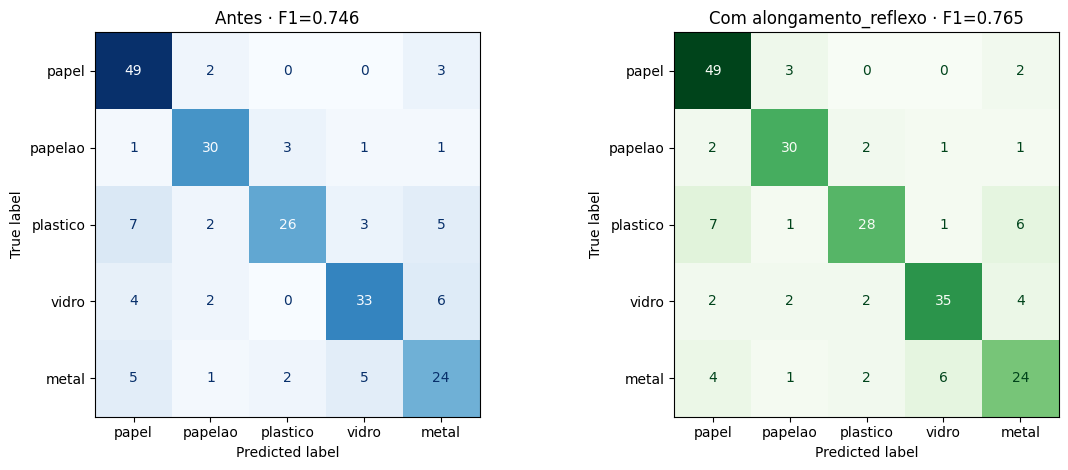

DECISÃO: manter alongamento_reflexo.


In [36]:
#@title ✨ ETAPA 3 · Testar alongamento do reflexo para METAL { display-mode: "form" }
from sklearn.base import clone

COLUNAS_ORIGINAIS = [
    "vermelho_medio", "verde_medio", "azul_medio",
    "vermelho_variacao", "verde_variacao", "azul_variacao",
    "brilho_medio", "contraste", "brilho_alto",
    "amplitude_luz", "bordas", "saturacao_media",
    "saturacao_variacao", "area_reluzente"
]

def avaliar_etapa3(colunas_teste):
    X_teste = X_caract[colunas_teste]
    Xt, Xv, yt, yv = train_test_split(
        X_teste, rotulos, test_size=tamanho_da_validacao/100,
        random_state=42, stratify=rotulos)
    modelo_teste = make_pipeline(StandardScaler(), clone(nucleo))
    modelo_teste.fit(Xt, yt)
    pred = modelo_teste.predict(Xv)
    return {
        "f1_macro": f1_score(yv, pred, average="macro"),
        "relatorio": classification_report(
            yv, pred, output_dict=True, zero_division=0),
        "matriz": confusion_matrix(yv, pred, labels=CLASSES),
        "previsoes": pred
    }

nucleo_referencia = clone(nucleo)
resultado_baseline = avaliar_etapa3(COLUNAS_ORIGINAIS)
COLUNAS_ETAPA3 = COLUNAS_ORIGINAIS + ["alongamento_reflexo"]
resultado_etapa3 = avaliar_etapa3(COLUNAS_ETAPA3)

f1_baseline = resultado_baseline["f1_macro"]
f1_etapa3 = resultado_etapa3["f1_macro"]
cm_baseline = resultado_baseline["matriz"]
cm_etapa3 = resultado_etapa3["matriz"]
idx_metal = CLASSES.index("metal")
idx_vidro = CLASSES.index("vidro")
idx_papel = CLASSES.index("papel")

print("=" * 62)
print("ETAPA 3 · ALONGAMENTO DO REFLEXO")
print("=" * 62)
print(f"F1 antigo:                 {f1_baseline:.4f}")
print(f"F1 novo:                   {f1_etapa3:.4f}")
print(f"Diferença:                 {f1_etapa3-f1_baseline:+.4f}")
print()
print(f"F1 metal antes:            {resultado_baseline['relatorio']['metal']['f1-score']:.4f}")
print(f"F1 metal depois:           {resultado_etapa3['relatorio']['metal']['f1-score']:.4f}")
print(f"metal → vidro antes/depois: {cm_baseline[idx_metal, idx_vidro]} → {cm_etapa3[idx_metal, idx_vidro]}")
print(f"metal → papel antes/depois: {cm_baseline[idx_metal, idx_papel]} → {cm_etapa3[idx_metal, idx_papel]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm_baseline, display_labels=CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Antes · F1={f1_baseline:.3f}")
ConfusionMatrixDisplay(cm_etapa3, display_labels=CLASSES).plot(
    ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title(f"Com alongamento_reflexo · F1={f1_etapa3:.3f}")
plt.tight_layout()
plt.show()

if f1_etapa3 > f1_baseline:
    colunas = COLUNAS_ETAPA3
    print("DECISÃO: manter alongamento_reflexo.")
else:
    colunas = COLUNAS_ORIGINAIS
    print("DECISÃO: não usar alongamento_reflexo no modelo.")

# Reconstrói as variáveis esperadas pelas próximas células do notebook.
X = X_caract[colunas]
y = rotulos
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)
nucleo = clone(nucleo_referencia)
modelo = make_pipeline(StandardScaler(), nucleo)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_valida)


ETAPA 4 · TEXTURA PARA PAPEL × PAPELÃO


,feature_testada,f1_antes,f1_depois,diferenca,decisao
0,variancia_laplaciano,0.7648,0.7653,+0.0006,manter
1,densidade_bordas,0.7653,0.8188,+0.0535,manter
2,glcm_contrast,0.8188,0.8244,+0.0057,manter
3,glcm_homogeneity,0.8244,0.8260,+0.0015,manter


F1 antes da etapa 4:       0.7648
F1 depois da etapa 4:      0.8260
Ganho da etapa:            +0.0612

F1 papel antes/depois:     0.8305 → 0.8376
F1 papelão antes/depois:   0.8219 → 0.8767
papel → papelão:           3 → 3
papelão → papel:           2 → 2


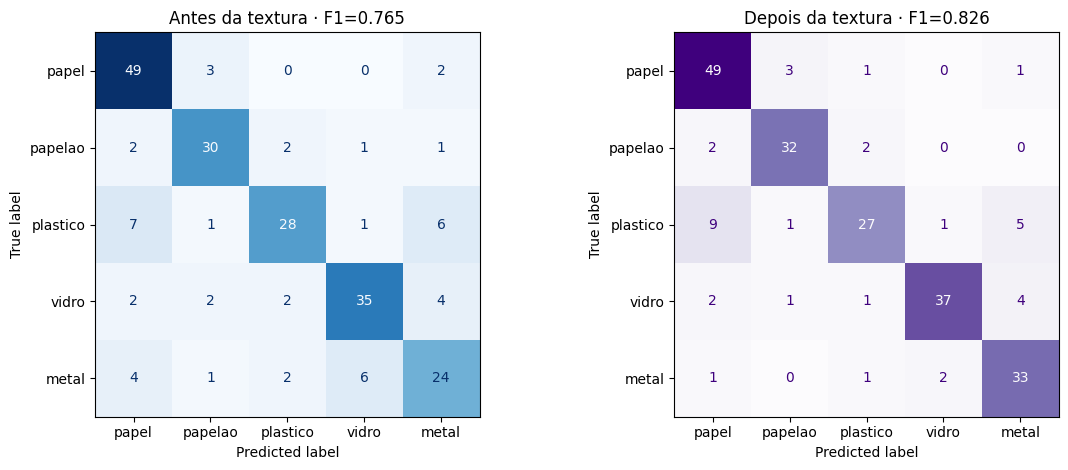

DECISÃO: manter apenas as features de textura com ganho incremental.
Features mantidas: ['variancia_laplaciano', 'densidade_bordas', 'glcm_contrast', 'glcm_homogeneity']


In [37]:
#@title 🧶 ETAPA 4 · Melhorar PAPEL × PAPELÃO com textura { display-mode: "form" }
FEATURES_TEXTURA = [
    "variancia_laplaciano",
    "densidade_bordas",
    "glcm_contrast",
    "glcm_homogeneity"
]

colunas_atuais = COLUNAS_ETAPA3.copy()
resultado_atual = avaliar_etapa3(colunas_atuais)
resultado_inicio_etapa4 = resultado_atual
comparacoes_textura = []

for feature in FEATURES_TEXTURA:
    colunas_candidatas = colunas_atuais + [feature]
    resultado_candidato = avaliar_etapa3(colunas_candidatas)
    diferenca = resultado_candidato["f1_macro"] - resultado_atual["f1_macro"]
    manter = diferenca > 0
    comparacoes_textura.append({
        "feature_testada": feature,
        "f1_antes": resultado_atual["f1_macro"],
        "f1_depois": resultado_candidato["f1_macro"],
        "diferenca": diferenca,
        "decisao": "manter" if manter else "remover"
    })
    if manter:
        colunas_atuais = colunas_candidatas
        resultado_atual = resultado_candidato

resultado_etapa4 = resultado_atual
f1_etapa4 = resultado_etapa4["f1_macro"]
cm_inicio_etapa4 = resultado_inicio_etapa4["matriz"]
cm_etapa4 = resultado_etapa4["matriz"]
idx_papelao = CLASSES.index("papelao")

print("=" * 68)
print("ETAPA 4 · TEXTURA PARA PAPEL × PAPELÃO")
print("=" * 68)
display(pd.DataFrame(comparacoes_textura).style.format({
    "f1_antes": "{:.4f}",
    "f1_depois": "{:.4f}",
    "diferenca": "{:+.4f}"
}))
print(f"F1 antes da etapa 4:       {resultado_inicio_etapa4['f1_macro']:.4f}")
print(f"F1 depois da etapa 4:      {f1_etapa4:.4f}")
print(f"Ganho da etapa:            {f1_etapa4-resultado_inicio_etapa4['f1_macro']:+.4f}")
print()
print(f"F1 papel antes/depois:     {resultado_inicio_etapa4['relatorio']['papel']['f1-score']:.4f} → {resultado_etapa4['relatorio']['papel']['f1-score']:.4f}")
print(f"F1 papelão antes/depois:   {resultado_inicio_etapa4['relatorio']['papelao']['f1-score']:.4f} → {resultado_etapa4['relatorio']['papelao']['f1-score']:.4f}")
print(f"papel → papelão:           {cm_inicio_etapa4[idx_papel, idx_papelao]} → {cm_etapa4[idx_papel, idx_papelao]}")
print(f"papelão → papel:           {cm_inicio_etapa4[idx_papelao, idx_papel]} → {cm_etapa4[idx_papelao, idx_papel]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm_inicio_etapa4, display_labels=CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Antes da textura · F1={resultado_inicio_etapa4['f1_macro']:.3f}")
ConfusionMatrixDisplay(cm_etapa4, display_labels=CLASSES).plot(
    ax=axes[1], cmap="Purples", colorbar=False)
axes[1].set_title(f"Depois da textura · F1={f1_etapa4:.3f}")
plt.tight_layout()
plt.show()

colunas = colunas_atuais
print("DECISÃO: manter apenas as features de textura com ganho incremental.")
print("Features mantidas:", [c for c in FEATURES_TEXTURA if c in colunas])

# Reconstrói o mesmo split e o mesmo SVM para as próximas células.
X = X_caract[colunas]
y = rotulos
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)
nucleo = clone(nucleo_referencia)
modelo = make_pipeline(StandardScaler(), nucleo)


ETAPA 5 · SATURAÇÃO PARA PLÁSTICO


,teste,f1_macro,f1_plastico,diferenca_macro
0,somente saturacao_p25,0.8380,0.7792,+0.0120
1,somente saturacao_p90,0.8176,0.7532,-0.0084
2,saturacao_p25 + saturacao_p90,0.8389,0.7949,+0.0130


F1 antes da etapa 5:         0.8260
F1 depois da etapa 5:        0.8389
Ganho da etapa:              +0.0130

F1 plástico antes/depois:    0.7200 → 0.7949
plástico → papel:             9 → 6
plástico → metal:             5 → 4


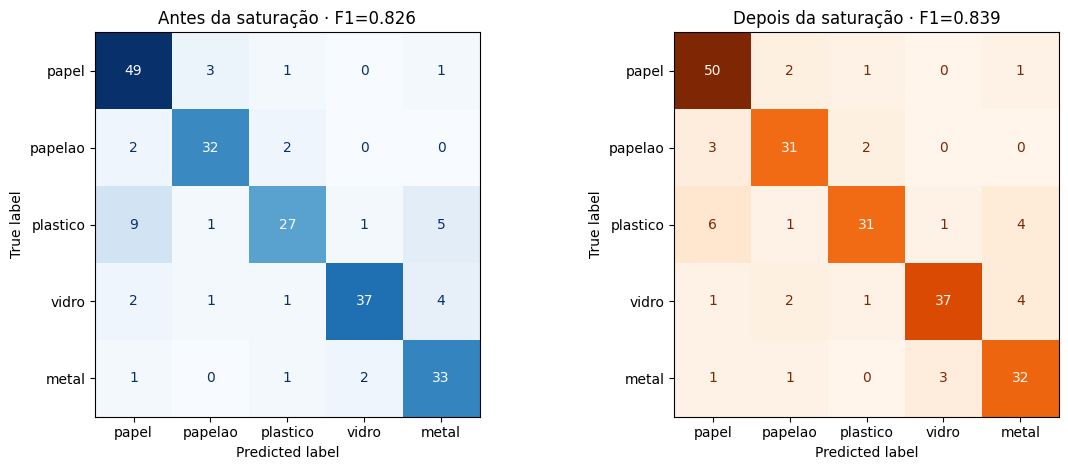

DECISÃO: manter ['saturacao_p25', 'saturacao_p90']


In [38]:
#@title 🎨 ETAPA 5 · Melhorar PLÁSTICO com saturação { display-mode: "form" }
resultado_inicio_etapa5 = avaliar_etapa3(colunas)
colunas_inicio_etapa5 = colunas.copy()

CANDIDATOS_SATURACAO = {
    "somente saturacao_p25": ["saturacao_p25"],
    "somente saturacao_p90": ["saturacao_p90"],
    "saturacao_p25 + saturacao_p90": ["saturacao_p25", "saturacao_p90"]
}

testes_saturacao = []
melhor_resultado_saturacao = resultado_inicio_etapa5
melhores_features_saturacao = []

for nome_teste, features_teste in CANDIDATOS_SATURACAO.items():
    resultado_teste = avaliar_etapa3(colunas_inicio_etapa5 + features_teste)
    diferenca = resultado_teste["f1_macro"] - resultado_inicio_etapa5["f1_macro"]
    testes_saturacao.append({
        "teste": nome_teste,
        "f1_macro": resultado_teste["f1_macro"],
        "f1_plastico": resultado_teste["relatorio"]["plastico"]["f1-score"],
        "diferenca_macro": diferenca
    })
    if resultado_teste["f1_macro"] > melhor_resultado_saturacao["f1_macro"]:
        melhor_resultado_saturacao = resultado_teste
        melhores_features_saturacao = features_teste

resultado_etapa5 = melhor_resultado_saturacao
f1_etapa5 = resultado_etapa5["f1_macro"]
cm_inicio_etapa5 = resultado_inicio_etapa5["matriz"]
cm_etapa5 = resultado_etapa5["matriz"]
idx_plastico = CLASSES.index("plastico")

print("=" * 68)
print("ETAPA 5 · SATURAÇÃO PARA PLÁSTICO")
print("=" * 68)
display(pd.DataFrame(testes_saturacao).style.format({
    "f1_macro": "{:.4f}",
    "f1_plastico": "{:.4f}",
    "diferenca_macro": "{:+.4f}"
}))
print(f"F1 antes da etapa 5:         {resultado_inicio_etapa5['f1_macro']:.4f}")
print(f"F1 depois da etapa 5:        {f1_etapa5:.4f}")
print(f"Ganho da etapa:              {f1_etapa5-resultado_inicio_etapa5['f1_macro']:+.4f}")
print()
print(f"F1 plástico antes/depois:    {resultado_inicio_etapa5['relatorio']['plastico']['f1-score']:.4f} → {resultado_etapa5['relatorio']['plastico']['f1-score']:.4f}")
print(f"plástico → papel:             {cm_inicio_etapa5[idx_plastico, idx_papel]} → {cm_etapa5[idx_plastico, idx_papel]}")
print(f"plástico → metal:             {cm_inicio_etapa5[idx_plastico, idx_metal]} → {cm_etapa5[idx_plastico, idx_metal]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm_inicio_etapa5, display_labels=CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Antes da saturação · F1={resultado_inicio_etapa5['f1_macro']:.3f}")
ConfusionMatrixDisplay(cm_etapa5, display_labels=CLASSES).plot(
    ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title(f"Depois da saturação · F1={f1_etapa5:.3f}")
plt.tight_layout()
plt.show()

if melhores_features_saturacao:
    colunas = colunas_inicio_etapa5 + melhores_features_saturacao
    print("DECISÃO: manter", melhores_features_saturacao)
else:
    colunas = colunas_inicio_etapa5
    print("DECISÃO: não manter novas features de saturação.")

# Reconstrói o mesmo split e o mesmo SVM para as próximas células.
X = X_caract[colunas]
y = rotulos
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)
nucleo = clone(nucleo_referencia)
modelo = make_pipeline(StandardScaler(), nucleo)


In [39]:
# ✏️ SUA VEZ · Parte 2: treinar e prever
# LACUNA 8 ▸ qual método ajusta os parâmetros do modelo às características de treino?
modelo.fit(X_treino, y_treino)

# LACUNA 9 ▸ qual método infere as classes de imagens que o modelo nunca viu?
previsoes = modelo.predict(X_valida)

print(f"Modelo ajustado. {len(previsoes)} previsões geradas para a validação.")


Modelo ajustado. 215 previsões geradas para a validação.


In [40]:
#@title 💡 ETAPA 6 · Brilho robusto à iluminação { display-mode: "form" }
resultado_inicio_etapa6 = avaliar_etapa3(colunas)
colunas_inicio_etapa6 = colunas.copy()
resultado_candidato_etapa6 = avaliar_etapa3(colunas + ["brilho_p90"])
ganho_etapa6 = (resultado_candidato_etapa6["f1_macro"] -
                resultado_inicio_etapa6["f1_macro"])

print("=" * 64)
print("ETAPA 6 · PERCENTIL DE BRILHO")
print("=" * 64)
print(f"F1 antigo:                 {resultado_inicio_etapa6['f1_macro']:.4f}")
print(f"F1 com brilho_p90:          {resultado_candidato_etapa6['f1_macro']:.4f}")
print(f"Diferença:                 {ganho_etapa6:+.4f}")

if ganho_etapa6 > 0:
    colunas = colunas_inicio_etapa6 + ["brilho_p90"]
    resultado_etapa6 = resultado_candidato_etapa6
    print("DECISÃO: manter brilho_p90.")
else:
    colunas = colunas_inicio_etapa6
    resultado_etapa6 = resultado_inicio_etapa6
    print("DECISÃO: não manter brilho_p90.")
f1_etapa6 = resultado_etapa6["f1_macro"]

X = X_caract[colunas]
y = rotulos
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)
nucleo = clone(nucleo_referencia)
modelo = make_pipeline(StandardScaler(), nucleo)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_valida)


ETAPA 6 · PERCENTIL DE BRILHO
F1 antigo:                 0.8389
F1 com brilho_p90:          0.8347
Diferença:                 -0.0043
DECISÃO: não manter brilho_p90.


In [41]:
#@title 🧩 ETAPA 7 · Comparar combinações de features { display-mode: "form" }
FEATURES_METAL = ["alongamento_reflexo"]
FEATURES_SATURACAO = ["saturacao_p25", "saturacao_p90"]
FEATURES_BRILHO = ["brilho_p90"]

COMBINACOES_FEATURES = {
    "A · originais": COLUNAS_ORIGINAIS,
    "B · originais + metal": COLUNAS_ORIGINAIS + FEATURES_METAL,
    "C · originais + textura": COLUNAS_ORIGINAIS + FEATURES_TEXTURA,
    "D · originais + saturação": COLUNAS_ORIGINAIS + FEATURES_SATURACAO,
    "E · originais + metal + textura": COLUNAS_ORIGINAIS + FEATURES_METAL + FEATURES_TEXTURA,
    "F · originais + metal + textura + saturação": COLUNAS_ORIGINAIS + FEATURES_METAL + FEATURES_TEXTURA + FEATURES_SATURACAO,
    "G · todas as aprovadas": COLUNAS_ORIGINAIS + FEATURES_METAL + FEATURES_TEXTURA + FEATURES_SATURACAO + FEATURES_BRILHO,
    "H · textura + saturação + brilho (sem alongamento)": COLUNAS_ORIGINAIS + FEATURES_TEXTURA + FEATURES_SATURACAO + FEATURES_BRILHO
}

resultados_combinacoes = []
melhor_nome_features = None
melhor_resultado_features = None
melhores_colunas = None

cv_robusto = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
total_conjuntos = len(COMBINACOES_FEATURES)

for indice, (nome_conjunto, colunas_teste) in enumerate(COMBINACOES_FEATURES.items(), 1):
    print(f"[{indice}/{total_conjuntos}] Testando {nome_conjunto}", flush=True)
    modelo_features = make_pipeline(
        StandardScaler(),
        SVC(C=100, kernel="rbf", gamma=0.03,
            class_weight="balanced", random_state=42, cache_size=1000))
    scores = cross_val_score(
        modelo_features, X_caract[colunas_teste], y,
        cv=cv_robusto, scoring="f1_macro", n_jobs=-1)
    resultado_teste = {"f1_macro": scores.mean(), "desvio": scores.std()}
    resultados_combinacoes.append({
        "conjunto_features": nome_conjunto,
        "quantidade": len(colunas_teste),
        "f1_macro_cv": resultado_teste["f1_macro"],
        "desvio_cv": resultado_teste["desvio"]
    })
    if (melhor_resultado_features is None or
            resultado_teste["f1_macro"] > melhor_resultado_features["f1_macro"]):
        melhor_nome_features = nome_conjunto
        melhor_resultado_features = resultado_teste
        melhores_colunas = colunas_teste.copy()
        print("=" * 62)
        print("NOVO MELHOR CONJUNTO DE FEATURES")
        print(f"Características ....... {nome_conjunto}")
        print(f"Quantidade ............ {len(colunas_teste)}")
        print(f"F1 médio CV ........... {scores.mean():.4f}")
        print(f"Desvio do F1 .......... {scores.std():.4f}")
        print("=" * 62)

ranking_features = pd.DataFrame(resultados_combinacoes).sort_values(
    "f1_macro_cv", ascending=False).reset_index(drop=True)
display(ranking_features.style.format({
    "f1_macro_cv": "{:.4f}", "desvio_cv": "{:.4f}"}))
print(f"Melhor conjunto: {melhor_nome_features}")
print(f"Quantidade de features: {len(melhores_colunas)}")
print(f"F1-macro médio CV: {melhor_resultado_features['f1_macro']:.4f}")

colunas = melhores_colunas.copy()
resultado_etapa7 = melhor_resultado_features
f1_etapa7 = resultado_etapa7["f1_macro"]
X = X_caract[colunas]
y = rotulos
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)


[1/8] Testando A · originais
NOVO MELHOR CONJUNTO DE FEATURES
Características ....... A · originais
Quantidade ............ 14
F1 médio CV ........... 0.7542
Desvio do F1 .......... 0.0205
[2/8] Testando B · originais + metal
[3/8] Testando C · originais + textura
NOVO MELHOR CONJUNTO DE FEATURES
Características ....... C · originais + textura
Quantidade ............ 18
F1 médio CV ........... 0.7792
Desvio do F1 .......... 0.0195
[4/8] Testando D · originais + saturação
[5/8] Testando E · originais + metal + textura
[6/8] Testando F · originais + metal + textura + saturação
NOVO MELHOR CONJUNTO DE FEATURES
Características ....... F · originais + metal + textura + saturação
Quantidade ............ 21
F1 médio CV ........... 0.7792
Desvio do F1 .......... 0.0227
[7/8] Testando G · todas as aprovadas
NOVO MELHOR CONJUNTO DE FEATURES
Características ....... G · todas as aprovadas
Quantidade ............ 22
F1 médio CV ........... 0.7846
Desvio do F1 .......... 0.0169
[8/8] Testando H · te

,conjunto_features,quantidade,f1_macro_cv,desvio_cv
0,H · textura + saturação + brilho (sem alongamento),21,0.7893,0.0154
1,G · todas as aprovadas,22,0.7846,0.0169
2,F · originais + metal + textura + saturação,21,0.7792,0.0227
3,C · originais + textura,18,0.7792,0.0195
4,D · originais + saturação,16,0.7697,0.0236
5,E · originais + metal + textura,19,0.7691,0.0160
6,A · originais,14,0.7542,0.0205
7,B · originais + metal,15,0.7412,0.0204


Melhor conjunto: H · textura + saturação + brilho (sem alongamento)
Quantidade de features: 21
F1-macro médio CV: 0.7893


In [42]:
#@title 🎯 ETAPA 8 · Tuning final do SVM { display-mode: "form" }
Cs = [10, 20, 30, 50, 75, 100, 150, 200]
gammas = [0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.04, 0.05, 0.07, 0.10]
peso_personalizado = {
    "papel": 1.0, "papelao": 1.09, "plastico": 1.23,
    "vidro": 1.05, "metal": 0.79
}
pesos = [None, "balanced", peso_personalizado]
total_configuracoes = len(Cs) * len(gammas) * len(pesos)
contador = 0
melhor_f1_tuning = -1
melhor_config_tuning = None

for C in Cs:
    for gamma in gammas:
        for peso in pesos:
            contador += 1
            print(f"[{contador}/{total_configuracoes}] Testando SVM", flush=True)
            nucleo_teste = SVC(
                C=C, kernel="rbf", gamma=gamma,
                class_weight=peso, random_state=42, cache_size=1000)
            modelo_teste = make_pipeline(StandardScaler(), nucleo_teste)
            scores_teste = cross_val_score(
                modelo_teste, X_caract[colunas], y, cv=cv_robusto,
                scoring="f1_macro", n_jobs=-1)
            f1_teste = scores_teste.mean()
            if f1_teste > melhor_f1_tuning:
                melhor_f1_tuning = f1_teste
                melhor_config_tuning = {
                    "C": C, "gamma": gamma, "class_weight": peso,
                    "desvio_cv": scores_teste.std()
                }
                print("=" * 62)
                print("NOVO MELHOR MODELO")
                print(f"Progresso ............ {contador}/{total_configuracoes}")
                print(f"C .................... {C}")
                print(f"Gamma ................ {gamma}")
                print(f"Class weight ......... {peso}")
                print(f"F1 médio CV .......... {f1_teste:.4f}")
                print(f"Desvio do F1 ......... {scores_teste.std():.4f}")
                print("=" * 62)

forca_C = melhor_config_tuning["C"]
modelo_escolhido = "SVM"
padronizar = True
nucleo = SVC(
    C=melhor_config_tuning["C"], kernel="rbf",
    gamma=melhor_config_tuning["gamma"],
    class_weight=melhor_config_tuning["class_weight"],
    random_state=42, cache_size=1000)
modelo = make_pipeline(StandardScaler(), nucleo)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_valida)
f1_holdout_etapa8 = f1_score(y_valida, previsoes, average="macro")
f1_etapa8 = melhor_f1_tuning
print(f"Tuning concluído. Melhor F1 médio CV: {f1_etapa8:.4f}")
print(f"F1 no recorte local de 10% (apenas diagnóstico): {f1_holdout_etapa8:.4f}")


[1/240] Testando SVM
NOVO MELHOR MODELO
Progresso ............ 1/240
C .................... 10
Gamma ................ 0.005
Class weight ......... None
F1 médio CV .......... 0.6893
Desvio do F1 ......... 0.0284
[2/240] Testando SVM
NOVO MELHOR MODELO
Progresso ............ 2/240
C .................... 10
Gamma ................ 0.005
Class weight ......... balanced
F1 médio CV .......... 0.6912
Desvio do F1 ......... 0.0268
[3/240] Testando SVM
[4/240] Testando SVM
NOVO MELHOR MODELO
Progresso ............ 4/240
C .................... 10
Gamma ................ 0.01
Class weight ......... None
F1 médio CV .......... 0.7139
Desvio do F1 ......... 0.0246
[5/240] Testando SVM
NOVO MELHOR MODELO
Progresso ............ 5/240
C .................... 10
Gamma ................ 0.01
Class weight ......... balanced
F1 médio CV .......... 0.7232
Desvio do F1 ......... 0.0344
[6/240] Testando SVM
[7/240] Testando SVM
NOVO MELHOR MODELO
Progresso ............ 7/240
C .................... 10
Gamma ...

CONFERÊNCIA FINAL
F1 baseline ............ 0.7463
F1 final médio CV ...... 0.7982
F1 no holdout de 10% ... 0.8234 (diagnóstico)
Ganho CV estimado ...... +0.0519
Features selecionadas ... 21
Parâmetros finais ....... {'C': 30, 'gamma': 0.07, 'class_weight': None, 'desvio_cv': np.float64(0.019107278509283458)}


,material,f1_baseline,f1_final,ganho
0,papel,0.8167,0.8305,+0.0138
1,papelao,0.8219,0.8571,+0.0352
2,plastico,0.7027,0.7949,+0.0922
3,vidro,0.7586,0.8095,+0.0509
4,metal,0.6316,0.8250,+0.1934


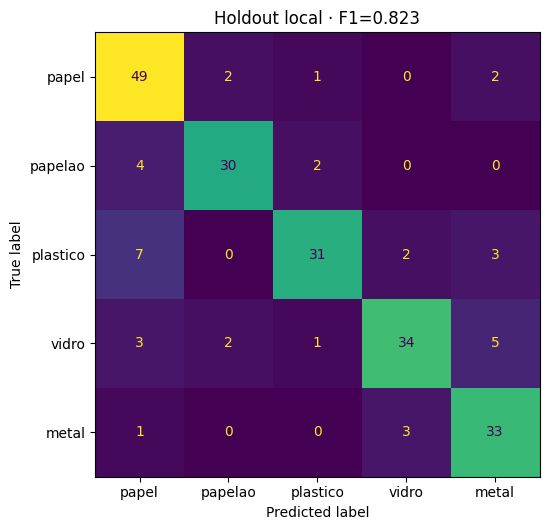

              precision    recall  f1-score   support

       metal      0.767     0.892     0.825        37
       papel      0.766     0.907     0.831        54
     papelao      0.882     0.833     0.857        36
    plastico      0.886     0.721     0.795        43
       vidro      0.872     0.756     0.810        45

    accuracy                          0.823       215
   macro avg      0.835     0.822     0.823       215
weighted avg      0.832     0.823     0.823       215



In [43]:
#@title ✅ ETAPA 9 · Conferência final do plano { display-mode: "form" }
f1_final_holdout = f1_score(y_valida, previsoes, average="macro")
f1_final_plano = melhor_f1_tuning
cm_final_plano = confusion_matrix(y_valida, previsoes, labels=CLASSES)
relatorio_final_plano = classification_report(
    y_valida, previsoes, output_dict=True, zero_division=0)

comparacao_classes = pd.DataFrame({
    "material": CLASSES,
    "f1_baseline": [resultado_baseline["relatorio"][c]["f1-score"] for c in CLASSES],
    "f1_final": [relatorio_final_plano[c]["f1-score"] for c in CLASSES]
})
comparacao_classes["ganho"] = (
    comparacao_classes["f1_final"] - comparacao_classes["f1_baseline"])

print("=" * 64)
print("CONFERÊNCIA FINAL")
print("=" * 64)
print(f"F1 baseline ............ {f1_baseline:.4f}")
print(f"F1 final médio CV ...... {f1_final_plano:.4f}")
print(f"F1 no holdout de 10% ... {f1_final_holdout:.4f} (diagnóstico)")
print(f"Ganho CV estimado ...... {f1_final_plano-f1_baseline:+.4f}")
print(f"Features selecionadas ... {len(colunas)}")
print(f"Parâmetros finais ....... {melhor_config_tuning}")
display(comparacao_classes.style.format({
    "f1_baseline": "{:.4f}", "f1_final": "{:.4f}", "ganho": "{:+.4f}"
}))

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ConfusionMatrixDisplay(cm_final_plano, display_labels=CLASSES).plot(
    ax=ax, cmap="viridis", colorbar=False)
ax.set_title(f"Holdout local · F1={f1_final_holdout:.3f}")
plt.tight_layout()
plt.show()
print(classification_report(y_valida, previsoes, digits=3))


FASE 1 · CONTAGEM DE REGIÕES DE REFLEXO
F1-macro antes:            0.8234
F1-macro depois:           0.8224
Diferença:                 -0.0010
F1 metal antes/depois:     0.8250 → 0.8101
metal → vidro antes/depois: 3 → 3
metal → papel antes/depois: 1 → 2


,material,f1_antes,f1_depois,diferenca
0,papel,0.8305,0.8421,+0.0116
1,papelao,0.8571,0.8451,-0.0121
2,plastico,0.7949,0.8101,+0.0153
3,vidro,0.8095,0.8046,-0.0049
4,metal,0.8250,0.8101,-0.0149


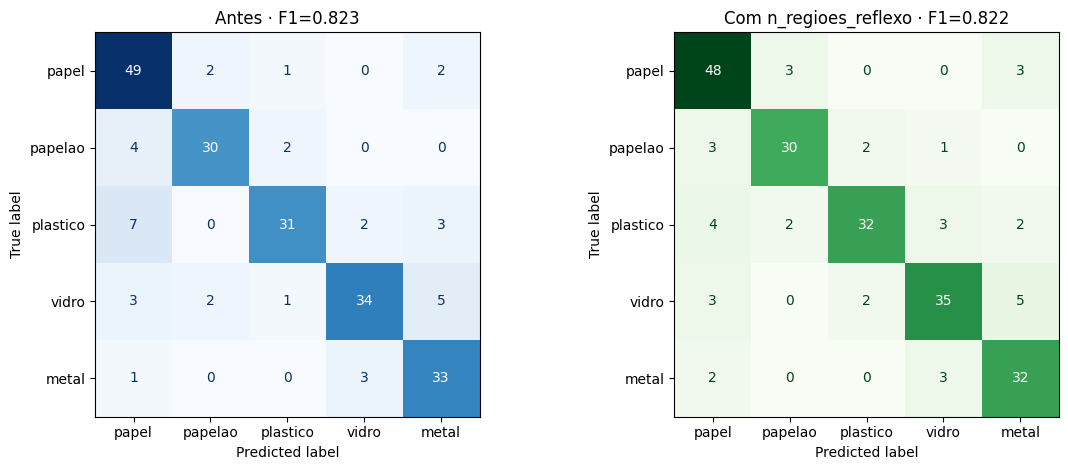

DECISÃO: REVERTIDA · n_regioes_reflexo fica fora do modelo.


In [44]:
#@title 🧪 FASE 1 · Contagem de regiões de reflexo { display-mode: "form" }
# Dependências: após alterar extrair_caracteristicas, reexecute Preparação,
# Extração de características, ETAPA 7, ETAPA 8 e então esta célula.
COLUNAS_BASE_FASE1 = melhores_colunas.copy()
COLUNAS_CANDIDATAS_FASE1 = COLUNAS_BASE_FASE1 + ["n_regioes_reflexo"]

def avaliar_fase1(colunas_teste):
    X_teste = X_caract[colunas_teste]
    Xt, Xv, yt, yv = train_test_split(
        X_teste, rotulos, test_size=tamanho_da_validacao/100,
        random_state=42, stratify=rotulos)
    nucleo_teste = SVC(
        C=melhor_config_tuning["C"], kernel="rbf",
        gamma=melhor_config_tuning["gamma"],
        class_weight=melhor_config_tuning["class_weight"],
        random_state=42, cache_size=1000)
    modelo_teste = make_pipeline(StandardScaler(), nucleo_teste)
    modelo_teste.fit(Xt, yt)
    pred = modelo_teste.predict(Xv)
    return {
        "f1_macro": f1_score(yv, pred, average="macro"),
        "relatorio": classification_report(
            yv, pred, output_dict=True, zero_division=0),
        "matriz": confusion_matrix(yv, pred, labels=CLASSES)
    }

resultado_antes_fase1 = avaliar_fase1(COLUNAS_BASE_FASE1)
resultado_depois_fase1 = avaliar_fase1(COLUNAS_CANDIDATAS_FASE1)
diferenca_fase1 = (resultado_depois_fase1["f1_macro"] -
                   resultado_antes_fase1["f1_macro"])
f1_metal_antes_fase1 = resultado_antes_fase1["relatorio"]["metal"]["f1-score"]
f1_metal_depois_fase1 = resultado_depois_fase1["relatorio"]["metal"]["f1-score"]
idx_metal = CLASSES.index("metal")
idx_vidro = CLASSES.index("vidro")
idx_papel = CLASSES.index("papel")
cm_antes_fase1 = resultado_antes_fase1["matriz"]
cm_depois_fase1 = resultado_depois_fase1["matriz"]

comparacao_classes_fase1 = pd.DataFrame({
    "material": CLASSES,
    "f1_antes": [resultado_antes_fase1["relatorio"][c]["f1-score"] for c in CLASSES],
    "f1_depois": [resultado_depois_fase1["relatorio"][c]["f1-score"] for c in CLASSES]
})
comparacao_classes_fase1["diferenca"] = (
    comparacao_classes_fase1["f1_depois"] - comparacao_classes_fase1["f1_antes"])

print("=" * 68)
print("FASE 1 · CONTAGEM DE REGIÕES DE REFLEXO")
print("=" * 68)
print(f"F1-macro antes:            {resultado_antes_fase1['f1_macro']:.4f}")
print(f"F1-macro depois:           {resultado_depois_fase1['f1_macro']:.4f}")
print(f"Diferença:                 {diferenca_fase1:+.4f}")
print(f"F1 metal antes/depois:     {f1_metal_antes_fase1:.4f} → {f1_metal_depois_fase1:.4f}")
print(f"metal → vidro antes/depois: {cm_antes_fase1[idx_metal, idx_vidro]} → {cm_depois_fase1[idx_metal, idx_vidro]}")
print(f"metal → papel antes/depois: {cm_antes_fase1[idx_metal, idx_papel]} → {cm_depois_fase1[idx_metal, idx_papel]}")
display(comparacao_classes_fase1.style.format({
    "f1_antes": "{:.4f}", "f1_depois": "{:.4f}", "diferenca": "{:+.4f}"
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm_antes_fase1, display_labels=CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Antes · F1={resultado_antes_fase1['f1_macro']:.3f}")
ConfusionMatrixDisplay(cm_depois_fase1, display_labels=CLASSES).plot(
    ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title(f"Com n_regioes_reflexo · F1={resultado_depois_fase1['f1_macro']:.3f}")
plt.tight_layout()
plt.show()

# Resultado medido da FASE 1: REVERTIDA (macro -0.0010; metal 0.8250 -> 0.8101).
# A tolerância de -0.002 não foi usada porque não houve ganho de robustez nem em metal.
# Regra conservadora do experimento: uma nova feature só entra se o F1-macro não cair.
manter_fase1 = diferenca_fase1 >= 0
if manter_fase1:
    colunas = COLUNAS_CANDIDATAS_FASE1.copy()
    FEATURES_APROVADAS_FASE1 = ["n_regioes_reflexo"]
    resultado_fase1 = resultado_depois_fase1
    print("DECISÃO: MANTIDA · n_regioes_reflexo entra no conjunto incremental.")
else:
    colunas = COLUNAS_BASE_FASE1.copy()
    FEATURES_APROVADAS_FASE1 = []
    resultado_fase1 = resultado_antes_fase1
    print("DECISÃO: REVERTIDA · n_regioes_reflexo fica fora do modelo.")

# Reconstrói o mesmo split/modelo para as células downstream.
X = X_caract[colunas]
y = rotulos
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)
nucleo = SVC(
    C=melhor_config_tuning["C"], kernel="rbf",
    gamma=melhor_config_tuning["gamma"],
    class_weight=melhor_config_tuning["class_weight"],
    random_state=42, cache_size=1000)
modelo = make_pipeline(StandardScaler(), nucleo)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_valida)


In [45]:
#@title 🧪 FASE 2 · Matiz circular em HSV { display-mode: "form" }
# Baseline: conjunto aprovado ao fim da FASE 1.
COLUNAS_BASE_FASE2 = colunas.copy()
FEATURES_FASE2 = ["hue_medio", "hue_variacao"]
resultado_antes_fase2 = avaliar_fase1(COLUNAS_BASE_FASE2)
resultado_depois_fase2 = avaliar_fase1(COLUNAS_BASE_FASE2 + FEATURES_FASE2)
diferenca_fase2 = (resultado_depois_fase2["f1_macro"] -
                   resultado_antes_fase2["f1_macro"])

print("=" * 68)
print("FASE 2 · MATIZ CIRCULAR EM HSV")
print("=" * 68)
print(f"F1-macro antes:          {resultado_antes_fase2['f1_macro']:.4f}")
print(f"F1-macro depois:         {resultado_depois_fase2['f1_macro']:.4f}")
print(f"Diferença:               {diferenca_fase2:+.4f}")
for classe in ["vidro", "plastico"]:
    antes = resultado_antes_fase2["relatorio"][classe]["f1-score"]
    depois = resultado_depois_fase2["relatorio"][classe]["f1-score"]
    print(f"F1 {classe:<9}:          {antes:.4f} → {depois:.4f}")

# Resultado medido: REVERTIDA (macro -0.0033; vidro também piorou).
manter_fase2 = diferenca_fase2 > 0
if manter_fase2:
    colunas = COLUNAS_BASE_FASE2 + FEATURES_FASE2
    FEATURES_APROVADAS_FASE2 = FEATURES_FASE2.copy()
    resultado_fase2 = resultado_depois_fase2
    print("DECISÃO: MANTIDA")
else:
    colunas = COLUNAS_BASE_FASE2.copy()
    FEATURES_APROVADAS_FASE2 = []
    resultado_fase2 = resultado_antes_fase2
    print("DECISÃO: REVERTIDA · hue fica fora do modelo.")


FASE 2 · MATIZ CIRCULAR EM HSV
F1-macro antes:          0.8234
F1-macro depois:         0.8201
Diferença:               -0.0033
F1 vidro    :          0.8095 → 0.8046
F1 plastico :          0.7949 → 0.8052
DECISÃO: REVERTIDA · hue fica fora do modelo.


In [46]:
#@title 🧪 FASE 3 · Assimetria e curtose do brilho { display-mode: "form" }
COLUNAS_BASE_FASE3 = colunas.copy()
FEATURES_FASE3 = ["brilho_assimetria", "brilho_curtose"]
resultado_antes_fase3 = avaliar_fase1(COLUNAS_BASE_FASE3)
resultado_depois_fase3 = avaliar_fase1(COLUNAS_BASE_FASE3 + FEATURES_FASE3)
diferenca_fase3 = (resultado_depois_fase3["f1_macro"] -
                   resultado_antes_fase3["f1_macro"])

comparacao_classes_fase3 = pd.DataFrame({
    "material": CLASSES,
    "f1_antes": [resultado_antes_fase3["relatorio"][c]["f1-score"] for c in CLASSES],
    "f1_depois": [resultado_depois_fase3["relatorio"][c]["f1-score"] for c in CLASSES]
})
comparacao_classes_fase3["diferenca"] = (
    comparacao_classes_fase3["f1_depois"] - comparacao_classes_fase3["f1_antes"])
print("=" * 68)
print("FASE 3 · FORMA DA DISTRIBUIÇÃO DE BRILHO")
print("=" * 68)
print(f"F1-macro antes:          {resultado_antes_fase3['f1_macro']:.4f}")
print(f"F1-macro depois:         {resultado_depois_fase3['f1_macro']:.4f}")
print(f"Diferença:               {diferenca_fase3:+.4f}")
display(comparacao_classes_fase3.style.format({
    "f1_antes": "{:.4f}", "f1_depois": "{:.4f}", "diferenca": "{:+.4f}"}))

# Resultado medido: MANTIDA (+0.0120 no F1-macro).
manter_fase3 = diferenca_fase3 > 0
if manter_fase3:
    colunas = COLUNAS_BASE_FASE3 + FEATURES_FASE3
    FEATURES_APROVADAS_FASE3 = FEATURES_FASE3.copy()
    resultado_fase3 = resultado_depois_fase3
    print("DECISÃO: MANTIDA · assimetria e curtose seguem como candidatas.")
else:
    colunas = COLUNAS_BASE_FASE3.copy()
    FEATURES_APROVADAS_FASE3 = []
    resultado_fase3 = resultado_antes_fase3
    print("DECISÃO: REVERTIDA")


FASE 3 · FORMA DA DISTRIBUIÇÃO DE BRILHO
F1-macro antes:          0.8234
F1-macro depois:         0.8354
Diferença:               +0.0120


,material,f1_antes,f1_depois,diferenca
0,papel,0.8305,0.8547,+0.0242
1,papelao,0.8571,0.8108,-0.0463
2,plastico,0.7949,0.8395,+0.0446
3,vidro,0.8095,0.8148,+0.0053
4,metal,0.8250,0.8571,+0.0321


DECISÃO: MANTIDA · assimetria e curtose seguem como candidatas.


In [47]:
#@title 🧪 FASE 4 · Energia periódica { display-mode: "form" }
COLUNAS_BASE_FASE4 = colunas.copy()
FEATURES_FASE4 = ["energia_periodica"]
resultado_antes_fase4 = avaliar_fase1(COLUNAS_BASE_FASE4)
resultado_depois_fase4 = avaliar_fase1(COLUNAS_BASE_FASE4 + FEATURES_FASE4)
diferenca_fase4 = (resultado_depois_fase4["f1_macro"] -
                   resultado_antes_fase4["f1_macro"])
ip, ic = CLASSES.index("papel"), CLASSES.index("papelao")
cm_antes_fase4 = resultado_antes_fase4["matriz"]
cm_depois_fase4 = resultado_depois_fase4["matriz"]
print("=" * 68)
print("FASE 4 · TEXTURA PERIÓDICA")
print("=" * 68)
print(f"F1-macro antes/depois:   {resultado_antes_fase4['f1_macro']:.4f} → {resultado_depois_fase4['f1_macro']:.4f}")
print(f"Diferença:               {diferenca_fase4:+.4f}")
for classe in ["papel", "papelao"]:
    antes = resultado_antes_fase4["relatorio"][classe]["f1-score"]
    depois = resultado_depois_fase4["relatorio"][classe]["f1-score"]
    print(f"F1 {classe:<9}:          {antes:.4f} → {depois:.4f}")
print(f"papel → papelao:         {cm_antes_fase4[ip, ic]} → {cm_depois_fase4[ip, ic]}")
print(f"papelao → papel:         {cm_antes_fase4[ic, ip]} → {cm_depois_fase4[ic, ip]}")

# Resultado medido: REVERTIDA (macro -0.0188 e ambos os F1-alvo pioraram).
manter_fase4 = diferenca_fase4 > 0
if manter_fase4:
    colunas = COLUNAS_BASE_FASE4 + FEATURES_FASE4
    FEATURES_APROVADAS_FASE4 = FEATURES_FASE4.copy()
    resultado_fase4 = resultado_depois_fase4
    print("DECISÃO: MANTIDA")
else:
    colunas = COLUNAS_BASE_FASE4.copy()
    FEATURES_APROVADAS_FASE4 = []
    resultado_fase4 = resultado_antes_fase4
    print("DECISÃO: REVERTIDA · energia_periodica fica fora do modelo.")


FASE 4 · TEXTURA PERIÓDICA
F1-macro antes/depois:   0.8354 → 0.8166
Diferença:               -0.0188
F1 papel    :          0.8547 → 0.8376
F1 papelao  :          0.8108 → 0.7733
papel → papelao:         3 → 4
papelao → papel:         3 → 3
DECISÃO: REVERTIDA · energia_periodica fica fora do modelo.


In [48]:
#@title 🧪 FASE 5 · GLCM energy/correlation { display-mode: "form" }
COLUNAS_BASE_FASE5 = colunas.copy()
FEATURES_FASE5 = ["glcm_energy", "glcm_correlation"]
resultado_antes_fase5 = avaliar_fase1(COLUNAS_BASE_FASE5)
resultado_depois_fase5 = avaliar_fase1(COLUNAS_BASE_FASE5 + FEATURES_FASE5)
diferenca_fase5 = (resultado_depois_fase5["f1_macro"] -
                   resultado_antes_fase5["f1_macro"])
print("=" * 68)
print("FASE 5 · GLCM ADICIONAIS")
print("=" * 68)
print(f"F1-macro antes:          {resultado_antes_fase5['f1_macro']:.4f}")
print(f"F1-macro depois:         {resultado_depois_fase5['f1_macro']:.4f}")
print(f"Diferença:               {diferenca_fase5:+.4f}")

# Resultado medido: REVERTIDA (-0.0169 no F1-macro).
manter_fase5 = diferenca_fase5 > 0
if manter_fase5:
    colunas = COLUNAS_BASE_FASE5 + FEATURES_FASE5
    FEATURES_APROVADAS_FASE5 = FEATURES_FASE5.copy()
    resultado_fase5 = resultado_depois_fase5
    print("DECISÃO: MANTIDA")
else:
    colunas = COLUNAS_BASE_FASE5.copy()
    FEATURES_APROVADAS_FASE5 = []
    resultado_fase5 = resultado_antes_fase5
    print("DECISÃO: REVERTIDA · GLCM adicionais ficam fora do modelo.")


FASE 5 · GLCM ADICIONAIS
F1-macro antes:          0.8354
F1-macro depois:         0.8185
Diferença:               -0.0169
DECISÃO: REVERTIDA · GLCM adicionais ficam fora do modelo.


In [49]:
#@title 🧪 FASE 6 · Proporção do objeto { display-mode: "form" }
COLUNAS_BASE_FASE6 = colunas.copy()
FEATURES_FASE6 = ["proporcao_objeto"]
resultado_antes_fase6 = avaliar_fase1(COLUNAS_BASE_FASE6)
resultado_depois_fase6 = avaliar_fase1(COLUNAS_BASE_FASE6 + FEATURES_FASE6)
diferenca_fase6 = (resultado_depois_fase6["f1_macro"] -
                   resultado_antes_fase6["f1_macro"])
print("=" * 68)
print("FASE 6 · PROPORÇÃO DO OBJETO")
print("=" * 68)
print(f"F1-macro antes:          {resultado_antes_fase6['f1_macro']:.4f}")
print(f"F1-macro depois:         {resultado_depois_fase6['f1_macro']:.4f}")
print(f"Diferença:               {diferenca_fase6:+.4f}")

# Resultado medido: REVERTIDA (-0.0210); a heurística frágil não foi tolerada.
manter_fase6 = diferenca_fase6 > 0
if manter_fase6:
    colunas = COLUNAS_BASE_FASE6 + FEATURES_FASE6
    FEATURES_APROVADAS_FASE6 = FEATURES_FASE6.copy()
    resultado_fase6 = resultado_depois_fase6
    print("DECISÃO: MANTIDA")
else:
    colunas = COLUNAS_BASE_FASE6.copy()
    FEATURES_APROVADAS_FASE6 = []
    resultado_fase6 = resultado_antes_fase6
    print("DECISÃO: REVERTIDA · proporcao_objeto fica fora do modelo.")


FASE 6 · PROPORÇÃO DO OBJETO
F1-macro antes:          0.8354
F1-macro depois:         0.8144
Diferença:               -0.0210
DECISÃO: REVERTIDA · proporcao_objeto fica fora do modelo.


In [50]:
#@title 🧪 FASE 7 · Nova seleção de features e tuning { display-mode: "form" }
# Compara as combinações originais com assimetria/curtose juntas e separadas.
f1_macro_cv_fase0 = float(melhor_f1_tuning)
colunas_fase0 = melhores_colunas.copy()
config_fase0 = melhor_config_tuning.copy()
resultados_fase7 = list(resultados_combinacoes)
melhor_nome_fase7 = melhor_nome_features
melhor_f1_selecao_fase7 = melhor_resultado_features["f1_macro"]
melhores_colunas_candidatas = melhores_colunas.copy()

VARIACOES_FASE7 = {
    "+ assimetria": ["brilho_assimetria"],
    "+ curtose": ["brilho_curtose"],
    "+ assimetria + curtose": ["brilho_assimetria", "brilho_curtose"]
}
for nome_base, colunas_base in COMBINACOES_FEATURES.items():
    for sufixo, acrescimo in VARIACOES_FASE7.items():
        colunas_teste = list(dict.fromkeys(colunas_base + acrescimo))
        modelo_teste = make_pipeline(
            StandardScaler(),
            SVC(C=100, kernel="rbf", gamma=0.03, class_weight="balanced",
                random_state=42, cache_size=1000))
        scores = cross_val_score(
            modelo_teste, X_caract[colunas_teste], rotulos,
            cv=cv_robusto, scoring="f1_macro", n_jobs=-1)
        media = scores.mean()
        nome = f"{nome_base} {sufixo}"
        resultados_fase7.append({
            "conjunto_features": nome,
            "quantidade": len(colunas_teste),
            "f1_macro_cv": media,
            "desvio_cv": scores.std()
        })
        if media > melhor_f1_selecao_fase7:
            melhor_nome_fase7 = nome
            melhor_f1_selecao_fase7 = media
            melhores_colunas_candidatas = colunas_teste.copy()

ranking_features_fase7 = pd.DataFrame(resultados_fase7).sort_values(
    "f1_macro_cv", ascending=False).reset_index(drop=True)
display(ranking_features_fase7.head(12).style.format({
    "f1_macro_cv": "{:.4f}", "desvio_cv": "{:.4f}"}))

# Tuning completo sobre o melhor conjunto ampliado.
Cs_fase7 = [10, 20, 30, 50, 75, 100, 150, 200]
gammas_fase7 = [0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.04, 0.05, 0.07, 0.10]
peso_personalizado_fase7 = {
    "papel": 1.0, "papelao": 1.09, "plastico": 1.23,
    "vidro": 1.05, "metal": 0.79
}
pesos_fase7 = [None, "balanced", peso_personalizado_fase7]
melhor_f1_candidato_fase7 = -1
melhor_config_candidata_fase7 = None
for C in Cs_fase7:
    for gamma in gammas_fase7:
        for peso in pesos_fase7:
            modelo_teste = make_pipeline(
                StandardScaler(),
                SVC(C=C, kernel="rbf", gamma=gamma, class_weight=peso,
                    random_state=42, cache_size=1000))
            scores = cross_val_score(
                modelo_teste, X_caract[melhores_colunas_candidatas], rotulos,
                cv=cv_robusto, scoring="f1_macro", n_jobs=-1)
            if scores.mean() > melhor_f1_candidato_fase7:
                melhor_f1_candidato_fase7 = scores.mean()
                melhor_config_candidata_fase7 = {
                    "C": C, "gamma": gamma, "class_weight": peso,
                    "desvio_cv": scores.std()
                }

if melhor_f1_candidato_fase7 >= f1_macro_cv_fase0:
    melhores_colunas = melhores_colunas_candidatas.copy()
    melhor_config_tuning = melhor_config_candidata_fase7.copy()
    melhor_f1_tuning = float(melhor_f1_candidato_fase7)
    melhor_nome_features = melhor_nome_fase7
    decisao_fase7 = "MANTIDA"
else:
    melhores_colunas = colunas_fase0.copy()
    melhor_config_tuning = config_fase0.copy()
    melhor_f1_tuning = f1_macro_cv_fase0
    melhor_nome_features = "Baseline correto da FASE 0"
    decisao_fase7 = "REVERTIDA"

colunas = melhores_colunas.copy()
forca_C = melhor_config_tuning["C"]
X = X_caract[colunas]
y = rotulos
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)
nucleo = SVC(
    C=melhor_config_tuning["C"], kernel="rbf",
    gamma=melhor_config_tuning["gamma"],
    class_weight=melhor_config_tuning["class_weight"],
    random_state=42, cache_size=1000)
modelo = make_pipeline(StandardScaler(), nucleo)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_valida)
f1_holdout_fase7 = f1_score(y_valida, previsoes, average="macro")
resultado_fase7 = {
    "f1_macro_cv_fase0": f1_macro_cv_fase0,
    "f1_macro_cv_fase7": melhor_f1_tuning,
    "diferenca": melhor_f1_tuning - f1_macro_cv_fase0,
    "decisao": decisao_fase7,
    "conjunto": melhor_nome_features,
    "quantidade": len(melhores_colunas),
    "config": melhor_config_tuning.copy()
}
print("=" * 72)
print("FASE 7 · RESULTADO FINAL DA SELEÇÃO E DO TUNING")
print("=" * 72)
print(f"F1-macro CV da FASE 0:   {f1_macro_cv_fase0:.4f}")
print(f"F1-macro CV da FASE 7:   {melhor_f1_tuning:.4f}")
print(f"Diferença:               {melhor_f1_tuning-f1_macro_cv_fase0:+.4f}")
print(f"Conjunto:                {melhor_nome_features}")
print(f"Quantidade:              {len(melhores_colunas)}")
print(f"Configuração:            {melhor_config_tuning}")
print(f"DECISÃO:                 {decisao_fase7}")
# Fotografia do baseline: reexecutar as células novas não muda a referência.
REFERENCIA_ESPACIAL = {
    "colunas": melhores_colunas.copy(),
    "modelo": clone(modelo),
    "parametros": nucleo.get_params().copy()
}


,conjunto_features,quantidade,f1_macro_cv,desvio_cv
0,H · textura + saturação + brilho (sem alongamento) + assimetria,22,0.7937,0.0221
1,H · textura + saturação + brilho (sem alongamento) + curtose,22,0.7930,0.0114
2,H · textura + saturação + brilho (sem alongamento) + assimetria + curtose,23,0.7919,0.0128
3,H · textura + saturação + brilho (sem alongamento),21,0.7893,0.0154
4,F · originais + metal + textura + saturação + curtose,22,0.7878,0.0170
5,G · todas as aprovadas + assimetria,23,0.7851,0.0207
6,G · todas as aprovadas,22,0.7846,0.0169
7,G · todas as aprovadas + curtose,23,0.7842,0.0133
8,C · originais + textura + curtose,19,0.7841,0.0090
9,C · originais + textura + assimetria,19,0.7835,0.0169


FASE 7 · RESULTADO FINAL DA SELEÇÃO E DO TUNING
F1-macro CV da FASE 0:   0.7982
F1-macro CV da FASE 7:   0.8024
Diferença:               +0.0042
Conjunto:                H · textura + saturação + brilho (sem alongamento) + assimetria
Quantidade:              22
Configuração:            {'C': 10, 'gamma': 0.07, 'class_weight': 'balanced', 'desvio_cv': np.float64(0.02130681489595229)}
DECISÃO:                 MANTIDA


### Nova abordagem: geometria dos reflexos e três classificadores

As fotos já são matrizes RGB de 48×48 pixels. RGB/255 põe os canais em [0,1];
`rgb2gray` calcula luminância ponderada. Isso é diferente de `StandardScaler`,
que aprende média/desvio entre amostras e fica dentro do Pipeline.

A carta descreve reflexos em faixas, mas não afirma que sejam sempre verticais
ou diagonais. Projeções e Hough medem localização, direção e concentração sem
fixar essa hipótese. Altura, largura, proporção e número de pixels são auditados;
colunas constantes são excluídas usando somente o treino de cada avaliação.
Os arquivos NPZ não fornecem tamanho original, EXIF, horário nem dados da câmera.

**Critérios definidos antes da busca:** adicionar uma coluna exige ganho médio
de pelo menos 0,005 de F1-macro em CV interna de 3 folds, com melhora em 2/3.
Remoção de coluna redundante aceita perda de até 0,001 na comparação pareada,
limitada a 0,002 no total da simplificação. Depois, cada candidata espacial é
avaliada individualmente; as aprovadas são auditadas novamente por remoção.

A avaliação externa reaproveita o `cv_robusto` estratificado de 5 folds.
Seleção, ranking de candidatas e tuning são refeitos somente no treino de cada
fold externo. Todos os algoritmos usam os mesmos folds. O holdout original de
10% permanece um diagnóstico: ele já foi consultado em experimentos anteriores.
O modelo anterior só é substituído com ganho externo >=0,005 e melhora em 4/5
folds. São critérios práticos de relevância/estabilidade, não prova de
significância estatística; os dados já foram explorados antes.

Fontes: [RGB/cinza](https://scikit-image.org/docs/0.25.x/api/skimage.color.html#skimage.color.rgb2gray),
[Hough](https://scikit-image.org/docs/0.25.x/auto_examples/edges/plot_line_hough_transform.html),
[seleção](https://scikit-learn.org/stable/modules/feature_selection.html),
[CV aninhada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

Reexecução: **Preparação → Extração → células originais até FASE 7 → novas
células A–D → Verificação → Resultado → Relatório → Submissão**.
As features rejeitadas continuam disponíveis para reproduzir experimentos,
mas não entram automaticamente no modelo final.


Formato treino/teste: (2150, 48, 48, 3) (240, 48, 48, 3)
Metadados disponíveis no NPZ: ['fotos', 'rotulos'] ['fotos']
Metadados constantes: {'meta_altura': 1, 'meta_largura': 1, 'meta_proporcao': 1, 'meta_pixels': 1}
Baseline congelado: 22 features


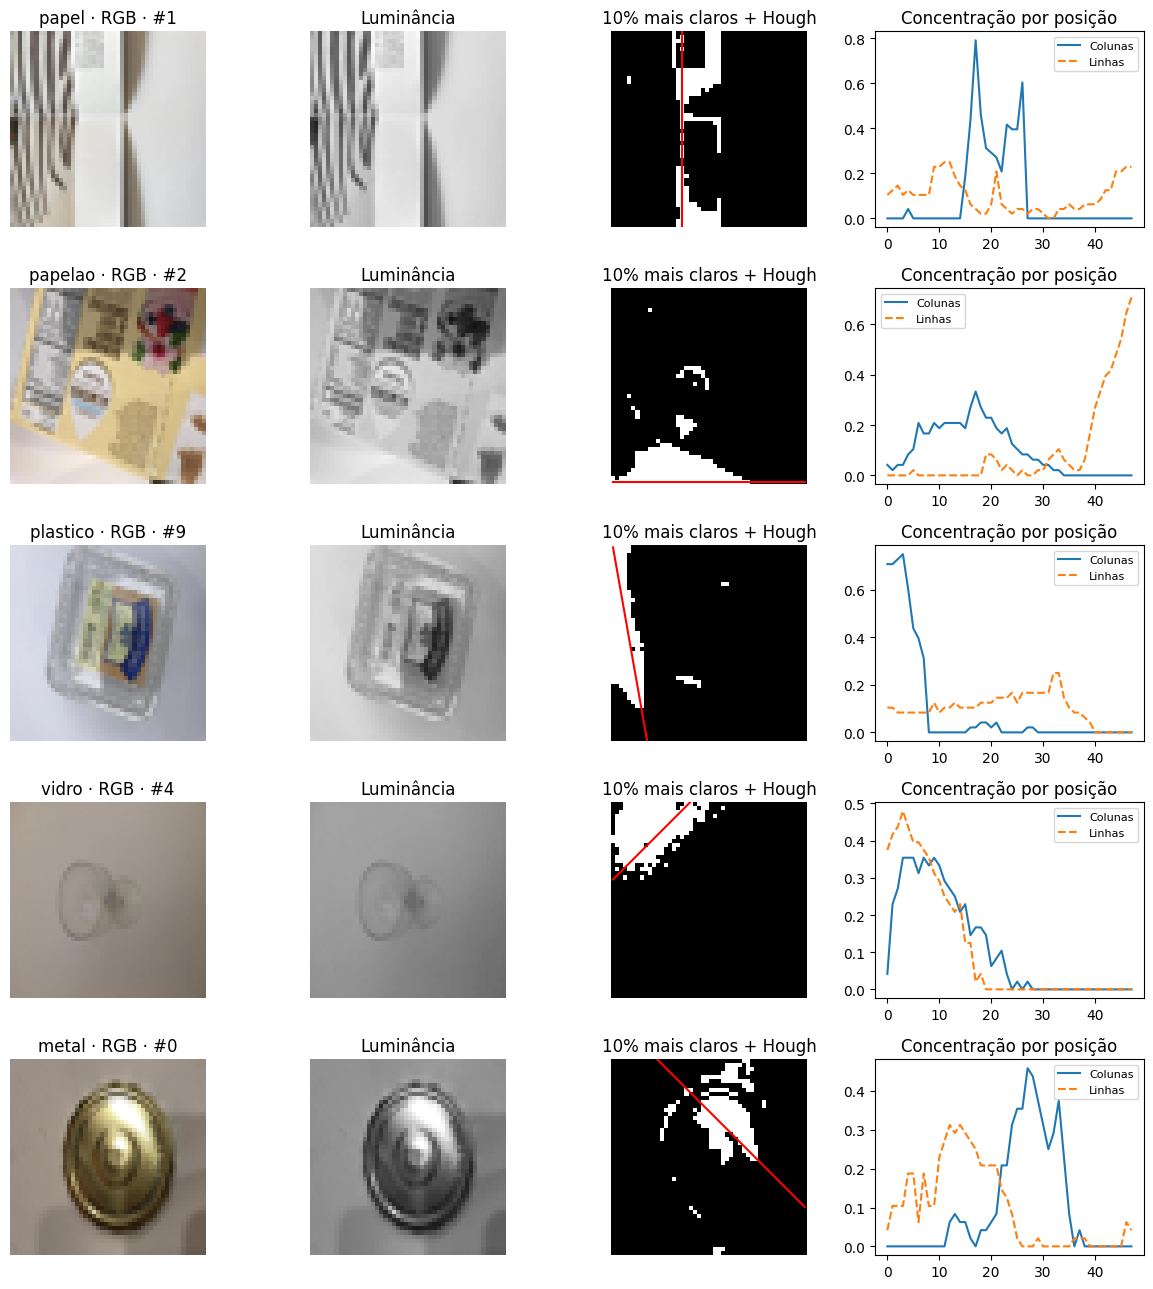

In [51]:
#@title A · Reconstrução RGB/cinza e localização de faixas
from sklearn.base import clone
from sklearn.feature_selection import f_classif
from sklearn.model_selection import ParameterGrid
from joblib import Parallel, delayed

if "REFERENCIA_ESPACIAL" not in globals():
    raise RuntimeError("Execute a FASE 7 para registrar o baseline antes da abordagem espacial.")
COLUNAS_REFERENCIA_ESPACIAL = REFERENCIA_ESPACIAL["colunas"].copy()
MODELO_REFERENCIA_ESPACIAL = clone(REFERENCIA_ESPACIAL["modelo"])
CONFIG_REFERENCIA_ESPACIAL = REFERENCIA_ESPACIAL["parametros"].copy()
CV_ESPACIAL = list(cv_robusto.split(X_caract, rotulos))
# Reutiliza os índices já produzidos pelo split original, sem inventar outro holdout.
INDICES_TREINO_ESPACIAL = X_treino.index.to_numpy().copy()
INDICES_VALIDA_ESPACIAL = X_valida.index.to_numpy().copy()
COLUNAS_CANDIDATAS_ESPACIAIS = list(descritores_espaciais(fotos[0]))
assert np.isfinite(X_caract.to_numpy()).all()
assert np.isfinite(X_caract_teste.to_numpy()).all()
assert X_caract.columns.equals(X_caract_teste.columns)
print("Formato treino/teste:", fotos.shape, fotos_teste.shape)
print("Metadados disponíveis no NPZ:", _treino.files, _teste.files)
print("Metadados constantes:", X_caract.filter(like="meta_").nunique().to_dict())
print("Baseline congelado:", len(COLUNAS_REFERENCIA_ESPACIAL), "features")
# Um exemplo por classe escolhido pela ordem, sem selecionar imagens pelo resultado.
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 13))
for linha, classe in enumerate(CLASSES):
    indice = int(np.flatnonzero(rotulos == classe)[0])
    rgb, cinza, mascara, hough, angulos, distancias = localizar_reflexos(fotos[indice])
    axes[linha, 0].imshow(rgb, interpolation="nearest")
    axes[linha, 0].set_title(f"{classe} · RGB · #{indice}")
    axes[linha, 1].imshow(cinza, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[linha, 1].set_title("Luminância")
    axes[linha, 2].imshow(mascara, cmap="gray", interpolation="nearest")
    axes[linha, 2].set_title("10% mais claros + Hough")
    if mascara.any():
        ir, it = np.unravel_index(hough.argmax(), hough.shape)
        theta, rho = angulos[it], distancias[ir]
        if abs(np.sin(theta)) > 1e-6:
            x = np.array([0, cinza.shape[1]-1])
            axes[linha, 2].plot(x, (rho-x*np.cos(theta))/np.sin(theta), "r-", lw=1.5)
        else:
            axes[linha, 2].axvline(rho/np.cos(theta), color="red", lw=1.5)
        axes[linha, 2].set_xlim(-.5, cinza.shape[1]-.5)
        axes[linha, 2].set_ylim(cinza.shape[0]-.5, -.5)
    axes[linha, 3].plot(mascara.mean(axis=0), label="Colunas")
    axes[linha, 3].plot(mascara.mean(axis=1), label="Linhas", linestyle="--")
    axes[linha, 3].set_title("Concentração por posição")
    axes[linha, 3].legend(fontsize=8)
    for coluna in range(3):
        axes[linha, coluna].set_axis_off()
plt.tight_layout()
plt.show()


In [52]:
#@title B · Seleção individual, tuning e comparação sem usar o fold externo
GANHO_MINIMO_COLUNA = 0.005
GANHO_MINIMO_MODELO = 0.005
TOLERANCIA_REMOCAO = 0.001
TOLERANCIA_TOTAL_REMOCAO = 0.002
N_JOBS_COMPARACAO = 3
FAMILIAS_ESPACIAIS = ["SVM", "Regressao Logistica", "Floresta Aleatoria"]

GRADES_ESPACIAIS = {
    "SVM": list(ParameterGrid({
        "C": [10, 30], "gamma": [0.03, 0.07], "class_weight": [None, "balanced"]})),
    "Regressao Logistica": list(ParameterGrid({
        "C": [0.1, 1.0, 10.0], "class_weight": [None, "balanced"]})),
    "Floresta Aleatoria": list(ParameterGrid({
        "min_samples_leaf": [1, 3], "max_features": ["sqrt", 0.7],
        "class_weight": [None, "balanced"]}))
}

def construir_modelo_espacial(familia, parametros):
    if familia == "SVM":
        return make_pipeline(StandardScaler(), SVC(
            **parametros, kernel="rbf", random_state=42, cache_size=300))
    if familia == "Regressao Logistica":
        return make_pipeline(StandardScaler(), LogisticRegression(
            **parametros, max_iter=3000, random_state=42))
    if familia == "Floresta Aleatoria":
        # Paralelismo nos folds; evita multiplicar threads dentro da floresta.
        return make_pipeline(RandomForestClassifier(
            **parametros, n_estimators=120, random_state=42, n_jobs=1))
    raise ValueError(f"Família desconhecida: {familia}")

def pontuar_folds_espacial(est, dados, alvos, cols, folds):
    # StandardScaler é ajustado pelo Pipeline apenas no treino de cada fold.
    return cross_val_score(
        est, dados[cols], alvos, cv=folds, scoring="f1_macro",
        n_jobs=1, error_score="raise")

def buscar_parametros_espacial(familia, dados, alvos, cols, folds):
    melhor = None
    for parametros in GRADES_ESPACIAIS[familia]:
        est = construir_modelo_espacial(familia, parametros)
        scores = pontuar_folds_espacial(est, dados, alvos, cols, folds)
        if melhor is None or scores.mean() > melhor["scores"].mean():
            melhor = {"parametros": parametros.copy(), "scores": scores}
    return melhor

def selecionar_colunas_espacial(familia, parametros, dados, alvos, folds):
    est = construir_modelo_espacial(familia, parametros)
    # Constantes só são identificadas no conjunto de TREINO recebido.
    variaveis = set(dados.columns[dados.nunique() > 1])
    cols = [c for c in COLUNAS_REFERENCIA_ESPACIAL if c in variaveis]
    scores = pontuar_folds_espacial(est, dados, alvos, cols, folds)
    inicial = scores.mean()
    auditoria = []

    def registrar(acao, coluna, anterior, novo, aceita):
        auditoria.append({
            "modelo": familia, "acao": acao, "coluna": coluna,
            "f1_antes": float(anterior.mean()), "f1_depois": float(novo.mean()),
            "delta": float((novo-anterior).mean()), "aceita": bool(aceita)
        })

    # Ablacao: coluna antiga nao recebe passe livre so por ja existir.
    for coluna in list(cols):
        if len(cols) <= 2:
            break
        teste = [c for c in cols if c != coluna]
        novo = pontuar_folds_espacial(est, dados, alvos, teste, folds)
        delta = novo-scores
        aceita = (
            delta.mean() >= -TOLERANCIA_REMOCAO
            and novo.mean() >= inicial-TOLERANCIA_TOTAL_REMOCAO
            and np.count_nonzero(delta >= -TOLERANCIA_REMOCAO) >= 2)
        registrar("remover_antiga", coluna, scores, novo, aceita)
        if aceita:
            cols, scores = teste, novo

    # Ranking serve apenas para ORDENAR os testes, nao para aceitar colunas.
    # O ranking usa exclusivamente o treino externo recebido.
    candidatas = [c for c in COLUNAS_CANDIDATAS_ESPACIAIS if c in variaveis and c not in cols]
    relevancias, _ = f_classif(dados[candidatas], alvos)
    ordem = np.argsort(-np.nan_to_num(relevancias, nan=0.0), kind="stable")
    candidatas = [candidatas[i] for i in ordem]
    for coluna in candidatas:
        novo = pontuar_folds_espacial(est, dados, alvos, cols+[coluna], folds)
        delta = novo-scores
        aceita = (
            delta.mean() >= GANHO_MINIMO_COLUNA
            and np.count_nonzero(delta > 0) >= 2)
        registrar("adicionar_espacial", coluna, scores, novo, aceita)
        if aceita:
            cols, scores = cols+[coluna], novo

    # Nova ablacao confere se colunas aceitas ficaram redundantes em conjunto.
    antes_limpeza = scores.mean()
    for coluna in [c for c in cols if c in COLUNAS_CANDIDATAS_ESPACIAIS]:
        teste = [c for c in cols if c != coluna]
        novo = pontuar_folds_espacial(est, dados, alvos, teste, folds)
        delta = novo-scores
        aceita = (
            delta.mean() >= -TOLERANCIA_REMOCAO
            and novo.mean() >= antes_limpeza-TOLERANCIA_TOTAL_REMOCAO
            and np.count_nonzero(delta >= -TOLERANCIA_REMOCAO) >= 2)
        registrar("remover_redundante", coluna, scores, novo, aceita)
        if aceita:
            cols, scores = teste, novo
    return cols, auditoria

def experimentar_familia_fold(familia, treino, valida, numero):
    dados, alvos = X_caract.iloc[treino], rotulos[treino]
    folds = list(StratifiedKFold(
        n_splits=3, shuffle=True, random_state=42).split(dados, alvos))
    ajuste_base = buscar_parametros_espacial(
        familia, dados, alvos, COLUNAS_REFERENCIA_ESPACIAL, folds)
    cols, auditoria = selecionar_colunas_espacial(
        familia, ajuste_base["parametros"], dados, alvos, folds)
    ajuste_novo = buscar_parametros_espacial(familia, dados, alvos, cols, folds)
    # O conjunto externo so aparece agora, apos TODAS as escolhas.
    base = construir_modelo_espacial(familia, ajuste_base["parametros"])
    novo = construir_modelo_espacial(familia, ajuste_novo["parametros"])
    base.fit(dados[COLUNAS_REFERENCIA_ESPACIAL], alvos)
    novo.fit(dados[cols], alvos)
    pred_base = base.predict(X_caract.iloc[valida][COLUNAS_REFERENCIA_ESPACIAL])
    pred_novo = novo.predict(X_caract.iloc[valida][cols])
    return {
        "familia": familia, "fold": numero, "indices": valida,
        "f1_base": float(f1_score(rotulos[valida], pred_base, average="macro")),
        "f1_novo": float(f1_score(rotulos[valida], pred_novo, average="macro")),
        "pred_base": pred_base, "pred_novo": pred_novo,
        "colunas": cols, "parametros": ajuste_novo["parametros"],
        "auditoria": auditoria
    }


In [53]:
#@title C · Validação externa e escolha do algoritmo
# O baseline conhecido e os três modelos usam os mesmos cinco folds externos.
scores_referencia_espacial = pontuar_folds_espacial(
    MODELO_REFERENCIA_ESPACIAL, X_caract, rotulos,
    COLUNAS_REFERENCIA_ESPACIAL, CV_ESPACIAL)
print("SVM anterior, CV reproduzida:", scores_referencia_espacial.mean(), flush=True)
resultados_externos_espaciais = []
for numero, (treino, valida) in enumerate(CV_ESPACIAL, 1):
    print(f"Fold externo {numero}/5: seleção individual + tuning dos três modelos...", flush=True)
    resultados_fold = Parallel(n_jobs=N_JOBS_COMPARACAO, prefer="threads")(
        delayed(experimentar_familia_fold)(familia, treino, valida, numero)
        for familia in FAMILIAS_ESPACIAIS)
    resultados_externos_espaciais.extend(resultados_fold)
    for r in resultados_fold:
        print(f"  {r['familia']}: base={r['f1_base']:.4f}; "
              f"selecionadas={r['f1_novo']:.4f}; {len(r['colunas'])} colunas", flush=True)

comparacoes_espaciais = []
for familia in FAMILIAS_ESPACIAIS:
    resultados = [r for r in resultados_externos_espaciais if r["familia"] == familia]
    scores = np.array([r["f1_novo"] for r in resultados])
    base_mesma_familia = np.array([r["f1_base"] for r in resultados])
    delta = scores - scores_referencia_espacial
    elegivel = delta.mean() >= GANHO_MINIMO_MODELO and np.count_nonzero(delta > 0) >= 4
    comparacoes_espaciais.append({
        "modelo": familia, "f1_base_22_features": float(base_mesma_familia.mean()),
        "f1_selecao_espacial": float(scores.mean()), "desvio_folds": float(scores.std()),
        "ganho_vs_svm_anterior": float(delta.mean()),
        "folds_melhores": int(np.count_nonzero(delta > 0)), "elegivel": bool(elegivel)
    })
ranking_modelos_espaciais = pd.DataFrame(comparacoes_espaciais).sort_values(
    "f1_selecao_espacial", ascending=False).reset_index(drop=True)
print(ranking_modelos_espaciais.to_string(index=False), flush=True)
elegiveis = ranking_modelos_espaciais[ranking_modelos_espaciais["elegivel"]]
familia_vencedora_espacial = elegiveis.iloc[0]["modelo"] if len(elegiveis) else None
print("Decisão externa:", familia_vencedora_espacial or "MANTER SVM ANTERIOR", flush=True)

# A busca final usa todos os dados publicos; o score reportado permanece externo.
auditoria_final_espacial = pd.DataFrame()
if familia_vencedora_espacial is not None:
    folds_internos_finais = list(StratifiedKFold(
        n_splits=3, shuffle=True, random_state=42).split(X_caract, rotulos))
    ajuste_base_final = buscar_parametros_espacial(
        familia_vencedora_espacial, X_caract, rotulos,
        COLUNAS_REFERENCIA_ESPACIAL, folds_internos_finais)
    colunas_finais_espaciais, auditoria = selecionar_colunas_espacial(
        familia_vencedora_espacial, ajuste_base_final["parametros"],
        X_caract, rotulos, folds_internos_finais)
    auditoria_final_espacial = pd.DataFrame(auditoria)
    ajuste_final_espacial = buscar_parametros_espacial(
        familia_vencedora_espacial, X_caract, rotulos,
        colunas_finais_espaciais, folds_internos_finais)
    modelo_final_template = construir_modelo_espacial(
        familia_vencedora_espacial, ajuste_final_espacial["parametros"])
    modelo_escolhido = familia_vencedora_espacial
    parametros_finais_espaciais = ajuste_final_espacial["parametros"].copy()
    linha_vencedora = elegiveis.iloc[0]
    f1_cv_modelo_final = float(linha_vencedora["f1_selecao_espacial"])
    protocolo_cv_final = "5 folds externos; selecao/tuning em 3 folds internos"
else:
    colunas_finais_espaciais = COLUNAS_REFERENCIA_ESPACIAL.copy()
    modelo_final_template = clone(MODELO_REFERENCIA_ESPACIAL)
    modelo_escolhido = "SVM"
    parametros_finais_espaciais = {
        k: CONFIG_REFERENCIA_ESPACIAL[k] for k in ["C", "gamma", "class_weight"]}
    f1_cv_modelo_final = float(scores_referencia_espacial.mean())
    protocolo_cv_final = "5 folds, baseline fixo anteriormente explorado"

# Variaveis downstream coerentes com o VENCEDOR, seja SVM, regressao ou floresta.
colunas = colunas_finais_espaciais.copy()
melhores_colunas = colunas.copy()
X = X_caract[colunas]
y = rotulos
X_treino = X.loc[INDICES_TREINO_ESPACIAL]
X_valida = X.loc[INDICES_VALIDA_ESPACIAL]
y_treino = rotulos[INDICES_TREINO_ESPACIAL]
y_valida = rotulos[INDICES_VALIDA_ESPACIAL]
modelo = clone(modelo_final_template)
modelo.fit(X_treino, y_treino)
nucleo = modelo.steps[-1][1]
padronizar = any(isinstance(etapa, StandardScaler) for _, etapa in modelo.steps)
forca_C = parametros_finais_espaciais.get("C")
previsoes = modelo.predict(X_valida)
f1_holdout_espacial = float(f1_score(y_valida, previsoes, average="macro"))
melhor_f1_tuning = f1_cv_modelo_final
melhor_config_tuning = parametros_finais_espaciais.copy()
conjunto_de_caracteristicas = "Seleção individual + geometria dos reflexos"
print("Colunas finais:", colunas, flush=True)
print("Parâmetros finais:", parametros_finais_espaciais, flush=True)
print("F1 CV externo:", f1_cv_modelo_final, flush=True)
print("Holdout original (diagnóstico):", f1_holdout_espacial, flush=True)
print("Decisões por coluna no ajuste final:", flush=True)
print(auditoria_final_espacial.to_string(index=False), flush=True)


SVM anterior, CV reproduzida: 0.8023746227433083
Fold externo 1/5: seleção individual + tuning dos três modelos...
  SVM: base=0.7741; selecionadas=0.7565; 21 colunas
  Regressao Logistica: base=0.6245; selecionadas=0.6133; 20 colunas
  Floresta Aleatoria: base=0.7269; selecionadas=0.7269; 22 colunas
Fold externo 2/5: seleção individual + tuning dos três modelos...
  SVM: base=0.7899; selecionadas=0.8002; 20 colunas
  Regressao Logistica: base=0.6498; selecionadas=0.6439; 20 colunas
  Floresta Aleatoria: base=0.7365; selecionadas=0.7583; 23 colunas
Fold externo 3/5: seleção individual + tuning dos três modelos...
  SVM: base=0.7893; selecionadas=0.7757; 19 colunas
  Regressao Logistica: base=0.6414; selecionadas=0.6607; 22 colunas
  Floresta Aleatoria: base=0.7577; selecionadas=0.7572; 19 colunas
Fold externo 4/5: seleção individual + tuning dos três modelos...
  SVM: base=0.8039; selecionadas=0.7913; 18 colunas
  Regressao Logistica: base=0.6538; selecionadas=0.6381; 20 colunas
  Flor

material  f1_referencia  f1_novo  delta
   papel       0.841418 0.841418    0.0
 papelao       0.845938 0.845938    0.0
plastico       0.773519 0.773519    0.0
   vidro       0.787258 0.787258    0.0
   metal       0.764858 0.764858    0.0
F1 OOF agregado: 0.802598315741404
F1 médio dos folds: 0.8023746227433083 (média por fold e OOF agregado são agregações diferentes)
metal -> vidro: 28 -> 28
metal -> papel: 14 -> 14
plastico -> papel: 29 -> 29
papel -> papelao: 17 -> 17
papelao -> papel: 24 -> 24


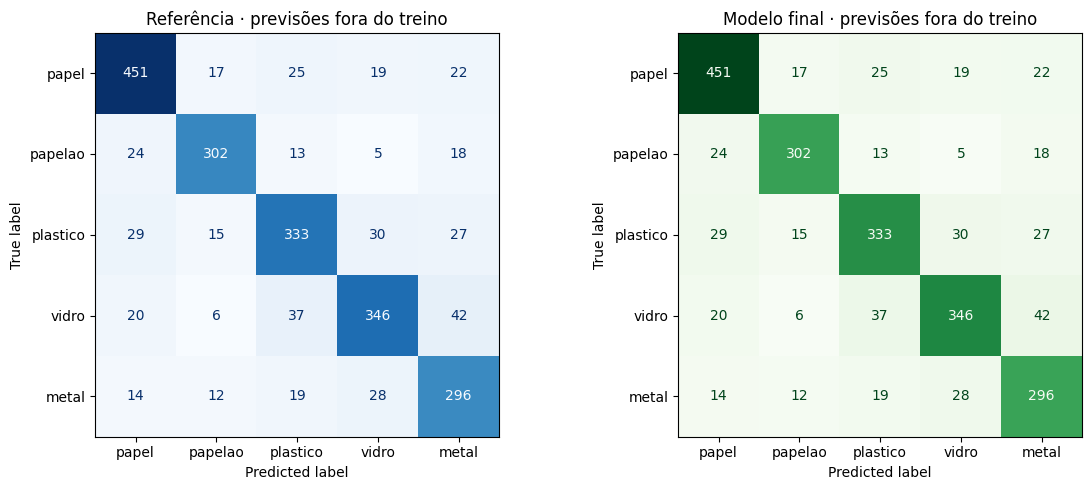

A busca avalia uma ordem sequencial de colunas, não todas as combinações possíveis.
O teste oficial não possui rótulos; seu desempenho permanece desconhecido.


In [54]:
#@title D · F1 por classe, estabilidade e erros fora do treino
pred_oof_referencia_espacial = np.empty_like(rotulos)
pred_oof_final_espacial = np.empty_like(rotulos)
for numero, (treino, valida) in enumerate(CV_ESPACIAL, 1):
    referencia = clone(MODELO_REFERENCIA_ESPACIAL)
    referencia.fit(X_caract.iloc[treino][COLUNAS_REFERENCIA_ESPACIAL], rotulos[treino])
    pred_oof_referencia_espacial[valida] = referencia.predict(
        X_caract.iloc[valida][COLUNAS_REFERENCIA_ESPACIAL])
    if familia_vencedora_espacial is None:
        pred_oof_final_espacial[valida] = pred_oof_referencia_espacial[valida]
    else:
        registro = next(r for r in resultados_externos_espaciais
                        if r["familia"] == familia_vencedora_espacial and r["fold"] == numero)
        pred_oof_final_espacial[valida] = registro["pred_novo"]
rep_ref = classification_report(
    rotulos, pred_oof_referencia_espacial, output_dict=True, zero_division=0)
rep_final = classification_report(
    rotulos, pred_oof_final_espacial, output_dict=True, zero_division=0)
comparacao_classes_espacial = pd.DataFrame({
    "material": CLASSES,
    "f1_referencia": [rep_ref[c]["f1-score"] for c in CLASSES],
    "f1_novo": [rep_final[c]["f1-score"] for c in CLASSES]})
comparacao_classes_espacial["delta"] = (
    comparacao_classes_espacial["f1_novo"] - comparacao_classes_espacial["f1_referencia"])
print(comparacao_classes_espacial.to_string(index=False))
print("F1 OOF agregado:", f1_score(rotulos, pred_oof_final_espacial, average="macro"))
print("F1 médio dos folds:", f1_cv_modelo_final,
      "(média por fold e OOF agregado são agregações diferentes)")
cm_ref = confusion_matrix(rotulos, pred_oof_referencia_espacial, labels=CLASSES)
cm_novo = confusion_matrix(rotulos, pred_oof_final_espacial, labels=CLASSES)
for real, previsto in [("metal", "vidro"), ("metal", "papel"),
                        ("plastico", "papel"), ("papel", "papelao"), ("papelao", "papel")]:
    i, j = CLASSES.index(real), CLASSES.index(previsto)
    print(f"{real} -> {previsto}: {cm_ref[i,j]} -> {cm_novo[i,j]}")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm_ref, display_labels=CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
ConfusionMatrixDisplay(cm_novo, display_labels=CLASSES).plot(
    ax=axes[1], cmap="Greens", colorbar=False)
axes[0].set_title("Referência · previsões fora do treino")
axes[1].set_title("Modelo final · previsões fora do treino")
plt.tight_layout()
plt.show()
if familia_vencedora_espacial:
    registros = [r for r in resultados_externos_espaciais
                 if r["familia"] == familia_vencedora_espacial]
    estabilidade_features_espacial = pd.Series(
        [c for r in registros for c in r["colunas"]]).value_counts()
    print("Frequência de seleção nos cinco treinos externos:")
    print(estabilidade_features_espacial.to_string())
print("A busca avalia uma ordem sequencial de colunas, não todas as combinações possíveis.")
print("O teste oficial não possui rótulos; seu desempenho permanece desconhecido.")


In [55]:
#@title 🔎 Verificação das lacunas { display-mode: "form" }
erros = []
try:
    _, cnt_t = np.unique(y_treino, return_counts=True)
    _, cnt_a = np.unique(y, return_counts=True)
    if np.abs(cnt_t/len(y_treino) - cnt_a/len(y)).max() > 0.04:
        erros.append("LACUNA 1: as proporções das classes no treino diferem do conjunto "
                     "completo. O argumento 'stratify' não recebeu o vetor correto.")
except NameError:
    erros.append("LACUNA 1: X_treino/y_treino não existem. Rode a Parte 1.")
try:
    esperado = {"Regressao Logistica": "LogisticRegression",
                "Floresta Aleatoria": "RandomForestClassifier",
                "SVM": "SVC"}[modelo_escolhido]
    if type(nucleo).__name__ != esperado:
        erros.append(f"LACUNAS 2 a 6: para '{modelo_escolhido}' era esperada a classe "
                     f"{esperado}, mas foi construída {type(nucleo).__name__}.")
except NameError:
    erros.append("LACUNAS 2 a 6: a variável 'nucleo' não existe.")
try:
    if padronizar:
        nomes = [type(p).__name__ for _, p in modelo.steps]
        if "StandardScaler" not in nomes:
            erros.append("LACUNA 7: a padronização está ligada, mas o Pipeline não contém "
                         "um StandardScaler.")
except (NameError, AttributeError):
    if padronizar: erros.append("LACUNA 7: o Pipeline não foi construído corretamente.")
try:
    treinado = hasattr(modelo, "classes_") or (hasattr(modelo, "steps") and
               hasattr(modelo.steps[-1][1], "classes_"))
    if not treinado:
        erros.append("LACUNA 8: o modelo não possui parâmetros ajustados.")
except NameError: pass
try:
    if len(previsoes) != len(X_valida):
        erros.append(f"LACUNA 9: {len(previsoes)} previsões para {len(X_valida)} casos.")
except NameError:
    erros.append("LACUNA 9: a variável 'previsoes' não existe.")

if erros:
    print("VERIFICAÇÃO REPROVADA. Pontos a revisar:\n")
    for e in erros: print("   [!] " + e + "\n")
else:
    print("VERIFICAÇÃO APROVADA\n")
    print("   Pipeline completo: dados estratificados, modelo construído e ajustado.")
    pad = {k: v for k, v in nucleo.get_params().items()
           if k in ("class_weight","min_samples_leaf","max_features","gamma","kernel",
                    "criterion","max_depth","degree")
           and v not in (None, 1, "sqrt", "scale", "rbf", "gini", 3)}
    if pad:
        print(f"\n   Parâmetros adicionais detectados na ZONA LIVRE: {pad}")
    else:
        print("\n   Nenhum parâmetro adicional foi declarado: o modelo usa os valores")
        print("   padrão. É válido, mas as tabelas do Bloco 2 dão margem real de melhoria.")

VERIFICAÇÃO APROVADA

   Pipeline completo: dados estratificados, modelo construído e ajustado.

   Parâmetros adicionais detectados na ZONA LIVRE: {'class_weight': 'balanced', 'gamma': 0.07}


---
# 📈 BLOCO 4 · AVALIAR
## *Onde a máquina se confunde?*

> **Rosa:** *"O número agregado me diz pouco. Preciso saber quais pares de material ele
> confunde. Vidro classificado como plástico vai para a prensa e danifica o equipamento.
> Papel classificado como papelão só reduz um pouco o preço do lote."*

A observação identifica com precisão o limite de qualquer métrica escalar: ela agrega erros
de naturezas e custos distintos em um único número. A matriz de confusão preserva a
estrutura dos erros, e é ela que orienta decisões de engenharia.


           DESEMPENHO NO CONJUNTO DE VALIDAÇÃO
  Acurácia (acertos no geral) ..........  82.3%
  ⭐ F1-MACRO (métrica oficial) .........  82.1%
  Desempenho alto. Verifiquem a estabilidade entre execuções.


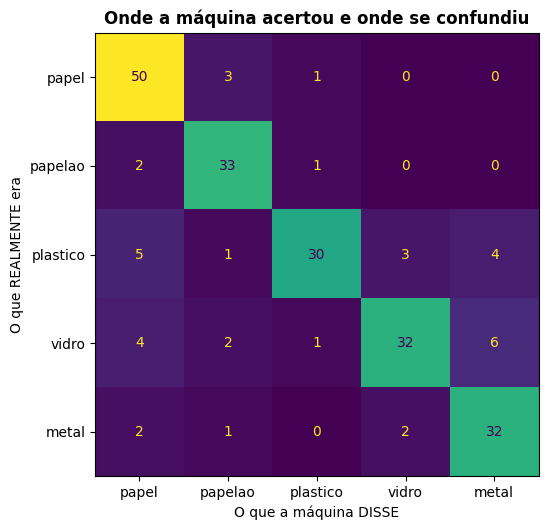


🔎 MAIORES CONFUSÕES DO MODELO:
   • 6 fotos de 🍾 VIDRO foram chamadas de 🥫 METAL
   • 5 fotos de 🧴 PLASTICO foram chamadas de 📄 PAPEL
   • 4 fotos de 🧴 PLASTICO foram chamadas de 🥫 METAL

   Analisem: quais descritores esses dois materiais compartilham, e que
   medida adicional permitiria separá-los?

              precision    recall  f1-score   support

       metal      0.762     0.865     0.810        37
       papel      0.794     0.926     0.855        54
     papelao      0.825     0.917     0.868        36
    plastico      0.909     0.698     0.789        43
       vidro      0.865     0.711     0.780        45

    accuracy                          0.823       215
   macro avg      0.831     0.823     0.821       215
weighted avg      0.831     0.823     0.821       215



In [56]:
#@title 🏆 O resultado da triagem automática { display-mode: "form" }
acuracia = accuracy_score(y_valida, previsoes)
f1 = f1_score(y_valida, previsoes, average="macro")

print("="*60)
print("           DESEMPENHO NO CONJUNTO DE VALIDAÇÃO")
print("="*60)
print(f"  Acurácia (acertos no geral) .......... {acuracia*100:5.1f}%")
print(f"  ⭐ F1-MACRO (métrica oficial) ......... {f1*100:5.1f}%")
print("="*60)
# Faixas calibradas nestes descritores: ~72% e o teto observado com boa configuração.
if   f1 >= .70: print("  Desempenho alto. Verifiquem a estabilidade entre execuções.")
elif f1 >= .64: print("  Desempenho sólido, com margem de otimização no Bloco 2.")
elif f1 >= .55: print("  Desempenho intermediário. Revisem o conjunto de características.")
else:           print("  Desempenho baixo. A representação atual não separa as classes.")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ConfusionMatrixDisplay(confusion_matrix(y_valida, previsoes, labels=CLASSES),
    display_labels=CLASSES).plot(ax=ax, cmap="viridis", colorbar=False)
ax.set_title("Onde a máquina acertou e onde se confundiu", fontweight="bold")
ax.set_xlabel("O que a máquina DISSE"); ax.set_ylabel("O que REALMENTE era")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_valida, previsoes, labels=CLASSES)
n = len(CLASSES)
confusoes = [(CLASSES[i], CLASSES[j], cm[i, j])
             for i in range(n) for j in range(n) if i != j and cm[i, j] > 0]
confusoes.sort(key=lambda t: -t[2])
print("\n🔎 MAIORES CONFUSÕES DO MODELO:")
if confusoes:
    for real, previsto, q in confusoes[:3]:
        print(f"   • {q} fotos de {EMOJI[real]} {real.upper()} "
              f"foram chamadas de {EMOJI[previsto]} {previsto.upper()}")
    print("\n   Analisem: quais descritores esses dois materiais compartilham, e que")
    print("   medida adicional permitiria separá-los?")
else:
    print("   Nenhuma! O modelo acertou todas as fotos do teste. 🎯")
print()
print(classification_report(y_valida, previsoes, digits=3))

if not padronizar and modelo_escolhido in ("Regressao Logistica", "SVM"):
    print("[!] O modelo escolhido é sensível à escala dos descritores e a")
    print("    padronização está DESLIGADA. Ligá-la no Bloco 2 costuma ser o")
    print("    ganho isolado mais relevante nesta trilha.")


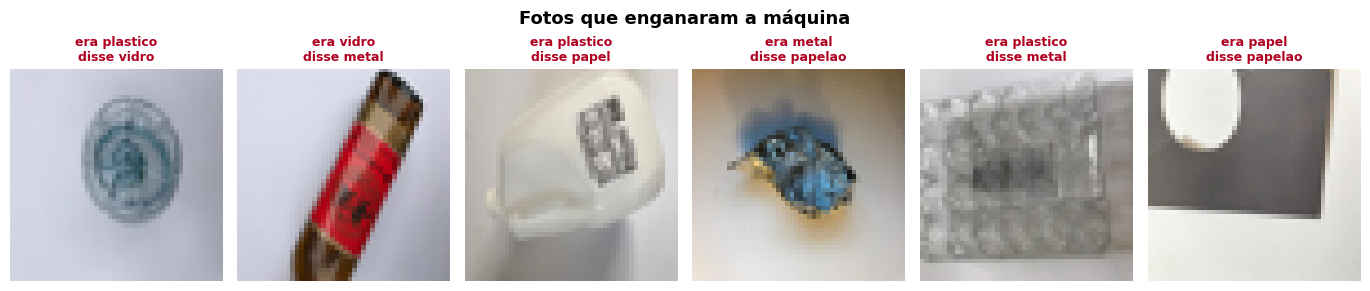

Classificações incorretas: 38 de 215 imagens.

A análise qualitativa de erros é prática padrão em visão computacional.
Examinem os casos acima e determinem:
   Um anotador humano classificaria essas imagens corretamente? Se não, o
   limite é da representação ou da própria qualidade do rótulo?
   Os erros compartilham alguma condição (baixa luminância, reflexo atípico)?
   Que descritor adicional capturaria a diferença que os atuais não capturam?


In [57]:
#@title 🕵️ A galeria dos erros { display-mode: "form" }
# A parte mais reveladora do desafio: **olhar as fotos que o modelo errou.**
idx_teste = X_valida.index.to_numpy()
y_valida_arr = np.asarray(y_valida)
errou = np.where(previsoes != y_valida_arr)[0]

if len(errou) == 0:
    print("🎯 Seu modelo não errou nenhuma foto do teste! Impressionante.")
else:
    n = min(6, len(errou))
    fig, axes = plt.subplots(1, n, figsize=(2.3*n, 3.1))
    if n == 1: axes = [axes]
    for ax, k in zip(axes, errou[:n]):
        ax.imshow(fotos[idx_teste[k]]); ax.axis("off")
        ax.set_title(f"era {y_valida_arr[k]}\ndisse {previsoes[k]}",
                     fontsize=9, color="#B00020", fontweight="bold")
    fig.suptitle("Fotos que enganaram a máquina", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()
    print(f"Classificações incorretas: {len(errou)} de {len(y_valida)} imagens.\n")
    print("A análise qualitativa de erros é prática padrão em visão computacional.")
    print("Examinem os casos acima e determinem:")
    print("   Um anotador humano classificaria essas imagens corretamente? Se não, o")
    print("   limite é da representação ou da própria qualidade do rótulo?")
    print("   Os erros compartilham alguma condição (baixa luminância, reflexo atípico)?")
    print("   Que descritor adicional capturaria a diferença que os atuais não capturam?")

---
# 🤔 PARADA OBRIGATÓRIA: uma conversa com a Dona Rosa

> **Rosa:** *"Tenho duas questões, e nenhuma delas é sobre o código de vocês."*
>
> *"A primeira é de governança. A cooperativa é autogestionária: as decisões passam por
> assembleia. Se eu levar uma ferramenta que altera o processo de trabalho, a assembleia
> vai perguntar quem decidiu implantá-la e sob quais condições. Sistemas assim costumam
> chegar prontos, decididos por quem não trabalha neles."*
>
> *"A segunda é econômica. Automação em triagem historicamente foi usada para reduzir
> postos, não para aliviar carga. A tecnologia não determina esse resultado, mas também não
> impede. Determina quem controla a implantação."*

### Questões para a equipe deliberar

1. **Deslocamento de domínio.** As imagens foram capturadas em um galpão específico, com
   iluminação e câmera específicas. Um modelo ajustado sobre esses descritores aprende, em
   parte, as condições da captura. Aplicado em outra cooperativa, com outra iluminação, o
   desempenho tende a cair mesmo com os mesmos materiais. Isso se chama **deslocamento de
   domínio** (*domain shift*) e é uma das principais causas de falha de sistemas de IA em
   produção. Como vocês testariam a exposição do modelo de vocês a esse risco, e o que
   fariam para mitigá-la?

2. **Autonomia da decisão.** Um sistema pode operar em modo autônomo, decidindo sozinho, ou
   em modo assistivo, sinalizando para decisão humana. Dada a taxa de erro que vocês
   mediram e o custo dos erros específicos que identificaram na matriz de confusão, qual
   dos dois regimes vocês recomendariam, e a partir de que desempenho a recomendação
   mudaria?

3. **Quem decide sobre a implantação.** A Rosa levanta uma questão que a literatura de
   tecnologia e trabalho trata há décadas: os efeitos da automação sobre o emprego dependem
   menos da técnica e mais de quem controla as decisões de implantação. Em uma cooperativa
   autogestionária, isso é decidido em assembleia. Que informação vocês precisariam entregar
   para que essa assembleia decidisse com autonomia real, e não apenas homologasse uma
   decisão técnica já tomada?

<img src="https://lh3.googleusercontent.com/d/11via5b3WO3iPrDtLkmXPWTynuAeHXGwt=w1600" width="100%"
     alt="Dois catadores trabalham na esteira ao lado de um braço robótico e de uma câmera com feixe ciano. No painel acima, ícones de lata, garrafa e papelão aparecem marcados como separados corretamente. Luz dourada de fim de tarde entra pela janela.">


In [58]:
#@title 📝 O relatório da sua equipe para a Dona Rosa { display-mode: "form" }
#@markdown Este texto vale nota e pode decidir o desempate.
nome_da_equipe = "Germinare"  #@param {type:"string"}
#@markdown **1. Quais características vocês usaram e por quê?**
resposta_1 = "Acabamos resolvendo usar todas as features, percebemos que certas informações só podem ser indentificadas pela luminosidade e outros pela cor, assim como Rosa comentou no seu e-mail. Além disso, realizamos o grid search, isto é, quando avaliamos combinações de features, modelos e parâmetros, para testar qual deles tem um melhor desempenho, e pode ser percebido que, para todos os modelos de teste (Regressão, Random Forest e o SVM) o resultado ficou melhor com a inclusão de todas as colunas. Aliás, eu julgaria como interessante realizar um teste de feature importante pós treinamento para validar a relevância de cada feature do modelo, para poder ter mais uma comprovação e justificativa para a escolha das features."  #@param {type:"string"}
#@markdown **2. Quais materiais o modelo mais confundiu? Por que vocês acham que isso acontece?**
resposta_2 = "Mesmo que em baixa quantidade, o maior erro do modelo foi classificar papel como metal. Acreditamos que isso ocorre porque algumas amostras de papel apresentam alto brilho, baixa saturação e reflexos semelhantes aos encontrados no metal, especialmente quando estão amassadas ou sob iluminação intensa."  #@param {type:"string"}
#@markdown **3. Regime de operação recomendado (autônomo ou assistivo) e justificativa.**
resposta_3 = "Acredito que seria interessante seguir com um modelo assistivo. Principalmente por ser um modelo novo, assim poderia ser validado a eficassia do modelo em um cenário real, validando assim um possível overfeat, mesmo que pouco provavel. Talvez no futuro, após o modelo se provar adequado, seja possível alterar a operação para que ela seja autônoma, pois ao meu etendimento do negócio, não há grande risco relacionado a classificação incorreta de alguns itens, mesmo sendo negativo e pela baixa margem de erro. Aliás, seria interessante perguntar à Rosa qual a margem de erro atual da linha, pois caso o modelo se provasse mais eficaz que o trabalho manual, não veria problema algum em fazer a substiuição total."  #@param {type:"string"}

relatorio = {"equipe": nome_da_equipe, "modelo": modelo_escolhido,
             "caracteristicas": conjunto_de_caracteristicas, "padronizar": padronizar,
             "C": forca_C, "teste_pct": tamanho_da_validacao,
             "f1_macro": round(f1, 4), "acuracia": round(acuracia, 4),
             "just_caracteristicas": resposta_1, "just_confusoes": resposta_2,
             "just_impacto": resposta_3}
faltando = [k for k in ["equipe", "just_caracteristicas", "just_confusoes", "just_impacto"]
            if not relatorio[k].strip()]
if faltando:
    print("⚠️ Ainda faltam campos:", ", ".join(faltando))
else:
    print("Relatório completo. Prossigam para a submissão.")

Relatório completo. Prossigam para a submissão.


In [60]:
#@title 🚀 Gerar o arquivo de submissão { display-mode: "form" }
#@markdown Execute a comparação espacial (célula C) antes de gerar os arquivos.
import json, pathlib
from sklearn.base import clone

necessarias = [
    "modelo_final_template", "colunas_finais_espaciais",
    "parametros_finais_espaciais", "f1_cv_modelo_final", "protocolo_cv_final"]
faltantes = [nome for nome in necessarias if nome not in globals()]
if faltantes:
    raise RuntimeError("Execute as células A, B e C da abordagem espacial antes da submissão. "
                       f"Variáveis ausentes: {', '.join(faltantes)}")
colunas = colunas_finais_espaciais.copy()
if not colunas or len(colunas) != len(set(colunas)):
    raise RuntimeError("Seleção final vazia ou com colunas duplicadas.")
if not set(colunas).issubset(X_caract_teste.columns):
    raise RuntimeError("Reexecute a extração: o teste está sem descritores selecionados.")

# Reconstrói exatamente a família vencedora. Não força SVC se outro modelo ganhar.
modelo_submissao = clone(modelo_final_template)
modelo_submissao.fit(X_caract[colunas], rotulos)
palpites = modelo_submissao.predict(X_caract_teste[colunas])
submissao = pd.DataFrame({"id_foto": np.arange(N_TESTE),
                          "material_previsto": palpites})
assert len(submissao) == N_TESTE
assert list(submissao.columns) == ["id_foto", "material_previsto"]
assert submissao["id_foto"].is_unique
assert submissao["material_previsto"].isin(CLASSES).all()

if "relatorio" not in globals() or not isinstance(relatorio, dict):
    relatorio = {"equipe": globals().get("nome_da_equipe", ""),
                 "just_impacto": globals().get("resposta_3", "")}
# Elimina parâmetros que não pertencem à família vencedora.
for chave in ["C", "gamma", "class_weight"]:
    relatorio.pop(chave, None)
relatorio.update({
    "modelo": modelo_escolhido,
    "caracteristicas": colunas.copy(),
    "quantidade_caracteristicas": len(colunas),
    "padronizar": padronizar,
    "parametros": parametros_finais_espaciais.copy(),
    "parametros_estimador": modelo_submissao.steps[-1][1].get_params(),
    **parametros_finais_espaciais,
    "teste_pct": tamanho_da_validacao,
    "f1_macro": float(f1_score(y_valida, previsoes, average="macro")),
    "acuracia": float(accuracy_score(y_valida, previsoes)),
    "f1_macro_cv": float(f1_cv_modelo_final),
    "protocolo_cv": protocolo_cv_final,
    "f1_macro_cv_referencia": float(scores_referencia_espacial.mean()),
    "comparacao_modelos": ranking_modelos_espaciais.to_dict(orient="records"),
    "just_caracteristicas": (
        f"Foram selecionadas {len(colunas)} medidas de cor, brilho, textura e/ou "
        "geometria de reflexos. Cada candidata espacial exige ganho interno de "
        f"pelo menos {GANHO_MINIMO_COLUNA:.3f} em F1-macro; colunas redundantes "
        "são avaliadas por remoção. O algoritmo e a seleção foram comparados em "
        "validação cruzada externa de 5 folds. Metadados constantes foram excluídos."),
})
cm_relatorio = confusion_matrix(y_valida, previsoes, labels=CLASSES)
confusoes_relatorio = sorted(
    [(int(cm_relatorio[i, j]), CLASSES[i], CLASSES[j])
     for i in range(len(CLASSES)) for j in range(len(CLASSES))
     if i != j and cm_relatorio[i, j]], reverse=True)
relatorio["just_confusoes"] = (
    "Maiores confusões no holdout original (diagnóstico): " +
    "; ".join(f"{real} -> {previsto}: {n}" for n, real, previsto in confusoes_relatorio[:3]) +
    ". Hipóteses sobre brilho e material exigem inspeção das imagens; a máscara "
    "de regiões claras também pode incluir fundo.")

assert relatorio["caracteristicas"] == colunas_finais_espaciais
assert relatorio["parametros"] == parametros_finais_espaciais
assert relatorio["f1_macro_cv"] == f1_cv_modelo_final
PASTA_SUBMISSAO = pathlib.Path("submissoes/visao")
PASTA_SUBMISSAO.mkdir(parents=True, exist_ok=True)
csv_saida = PASTA_SUBMISSAO / "submissao_visao.csv"
json_saida = PASTA_SUBMISSAO / "relatorio_visao.json"
submissao.to_csv(csv_saida, index=False)
with open(json_saida, "w", encoding="utf-8") as f:
    json.dump(relatorio, f, ensure_ascii=False, indent=2)

print(f"Modelo: {modelo_escolhido}; descritores: {len(colunas)}")
print("Parâmetros:", parametros_finais_espaciais)
print(f"F1-macro CV: {f1_cv_modelo_final:.4f} ({protocolo_cv_final})")
print(f"CSV: {len(submissao)} linhas; relatório: {json_saida}")
try:
    from google.colab import files
    files.download(str(csv_saida))
    files.download(str(json_saida))
except ImportError:
    print("Arquivos locais:", PASTA_SUBMISSAO.resolve())


Modelo: SVM; descritores: 22
Parâmetros: {'C': 10, 'gamma': 0.07, 'class_weight': 'balanced'}
F1-macro CV: 0.8024 (5 folds, baseline fixo anteriormente explorado)
CSV: 240 linhas; relatório: submissoes\visao\relatorio_visao.json
Arquivos locais: C:\Users\karinamartins-ieg\OneDrive - Instituto J&F\Área de Trabalho\germinare\CEIA\submissoes\visao


---
# 🌟 FIM DA MISSÃO RECOMEÇO

> **Rosa:** *"Levamos a proposta de vocês à assembleia. Aprovamos em regime assistivo: a
> máquina sinaliza, a pessoa confirma. Foi a recomendação de vocês e foi também o que a
> assembleia entendeu como aceitável."*
>
> *"O primeiro lote saiu sem contaminação e recebemos o valor integral. Mas o que fez
> diferença na discussão não foi o número de acerto. Foi vocês terem descrito onde o modelo
> falha e sob quais condições ele deixa de valer. Isso permitiu decidir com informação."*

---

### Competências desenvolvidas neste desafio

- O problema da representação em dados não estruturados
- Extração de características e redução de dimensionalidade
- A separação entre representação e classificação como princípio de projeto
- O papel do conhecimento de domínio na engenharia de atributos
- Sensibilidade de algoritmos à escala das variáveis, e quando padronizar
- `Pipeline` como mecanismo de disciplina no ajuste de transformações
- Análise qualitativa de erros e leitura estrutural da matriz de confusão
- Deslocamento de domínio como causa de falha em produção
- Regimes de autonomia e governança de sistemas automatizados

**Otimização.** Alterem **um fator por vez** e registrem o efeito: conjunto de
características, algoritmo, padronização, valor de C. Comparações válidas exigem isolar a
variável manipulada.
